In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
#Develop a function to count the number of patients
#& the the number of hours that contain a sepsis label
def analyze_hospital(folder):
    patients = []
    positive_hours = 0
    total_hours = 0

    for file in Path(folder).glob("*.psv"):
        df = pd.read_csv(file, sep="|", usecols=["SepsisLabel"])

        patients.append(df["SepsisLabel"].max())
        positive_hours += df["SepsisLabel"].sum()
        total_hours += len(df)

    return patients, positive_hours, total_hours


patients_A, positive_hours_A, total_hours_A = analyze_hospital( r"C:\Users\bJawh\PycharmProjects\Intro2ML_Project\sepsis_dataset\training_setA")

patients_B, positive_hours_B, total_hours_B = analyze_hospital(
    r"C:\Users\bJawh\PycharmProjects\Intro2ML_Project\sepsis_dataset\training_setB")

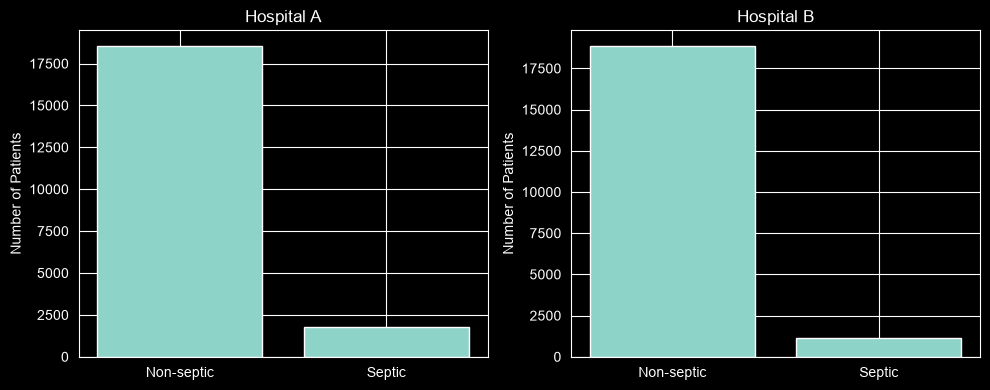

In [2]:

#Count septic and non-septic patients
counts_A = [patients_A.count(0), patients_A.count(1)]
counts_B = [patients_B.count(0), patients_B.count(1)]

# Create two plots
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
# use plt.bar to set the labels for the two bars and use the counts obtained for the values
plt.bar(["Non-septic", "Septic"], counts_A)
plt.title("Hospital A")
plt.ylabel("Number of Patients")

plt.subplot(1, 2, 2)
plt.bar(["Non-septic", "Septic"], counts_B)
plt.title("Hospital B")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()

In [3]:
for hospital, patients, positive_hours, total_hours in [
    ("Hospital A", patients_A, positive_hours_A, total_hours_A),
    ("Hospital B", patients_B, positive_hours_B, total_hours_B)
]:

    total_patients = len(patients)
    septic = patients.count(1)
    non_septic = patients.count(0)
    negative_hours = total_hours - positive_hours

    print(f"\n{hospital}")
    print(f"Total patients: {total_patients:,}")
    print(f"Septic patients: {septic:,} ({septic / total_patients * 100:.2f}%)")
    print(f"Non-septic patients: {non_septic:,} ({non_septic / total_patients * 100:.2f}%)")

    print(f"\nTotal hourly observations: {total_hours:,}")
    print(f"Positive hours: {positive_hours:,} ({positive_hours / total_hours * 100:.2f}%)")
    print(f"Negative hours: {negative_hours:,} ({negative_hours / total_hours * 100:.2f}%)")

    print(f"\nAverage recorded ICU hours per patient: {total_hours / total_patients:.2f}")


Hospital A
Total patients: 20,336
Septic patients: 1,790 (8.80%)
Non-septic patients: 18,546 (91.20%)

Total hourly observations: 790,215
Positive hours: 17,136 (2.17%)
Negative hours: 773,079 (97.83%)

Average recorded ICU hours per patient: 38.86

Hospital B
Total patients: 20,000
Septic patients: 1,142 (5.71%)
Non-septic patients: 18,858 (94.29%)

Total hourly observations: 761,995
Positive hours: 10,780 (1.41%)
Negative hours: 751,215 (98.59%)

Average recorded ICU hours per patient: 38.10


The results show that both hospitals have a highly imbalanced dataset, with only 8.80% of patients in Hospital A and 5.71% in Hospital B developing sepsis. This imbalance is even more noticeable at the hourly level, where positive labels represent only 2.17% and 1.41% of observations, respectively. Since our models will make predictions every hour, this means that a model could achieve high accuracy by mostly predicting the negative class, while failing to identify sepsis. Therefore, evaluation metrics such as AUPRC, recall, and clinical utility will be particularly important. Another observation is that sepsis prevalence is lower in Hospital B, which could affect model performance when training on Hospital A and testing on Hospital B. On the other hand, the average recording duration is similar in both hospitals, at approximately 38 hours. Overall, these findings highlight the need to account for class imbalance and carefully evaluate how well our models generalize across hospitals.


In [4]:
def analyze_missingness(folder):
    missing = None
    total_hours = 0

    for file in Path(folder).glob("*.psv"):
        df = pd.read_csv(file, sep="|")

        if missing is None:
            missing = pd.Series(0, index=df.columns)

        missing += df.isna().sum()
        total_hours += len(df)

    return missing / total_hours * 100

In [5]:
missing_A = analyze_missingness(
    r"C:\Users\bJawh\PycharmProjects\Intro2ML_Project\sepsis_dataset\training_setA"
)

missing_B = analyze_missingness(
    r"C:\Users\bJawh\PycharmProjects\Intro2ML_Project\sepsis_dataset\training_setB"
)

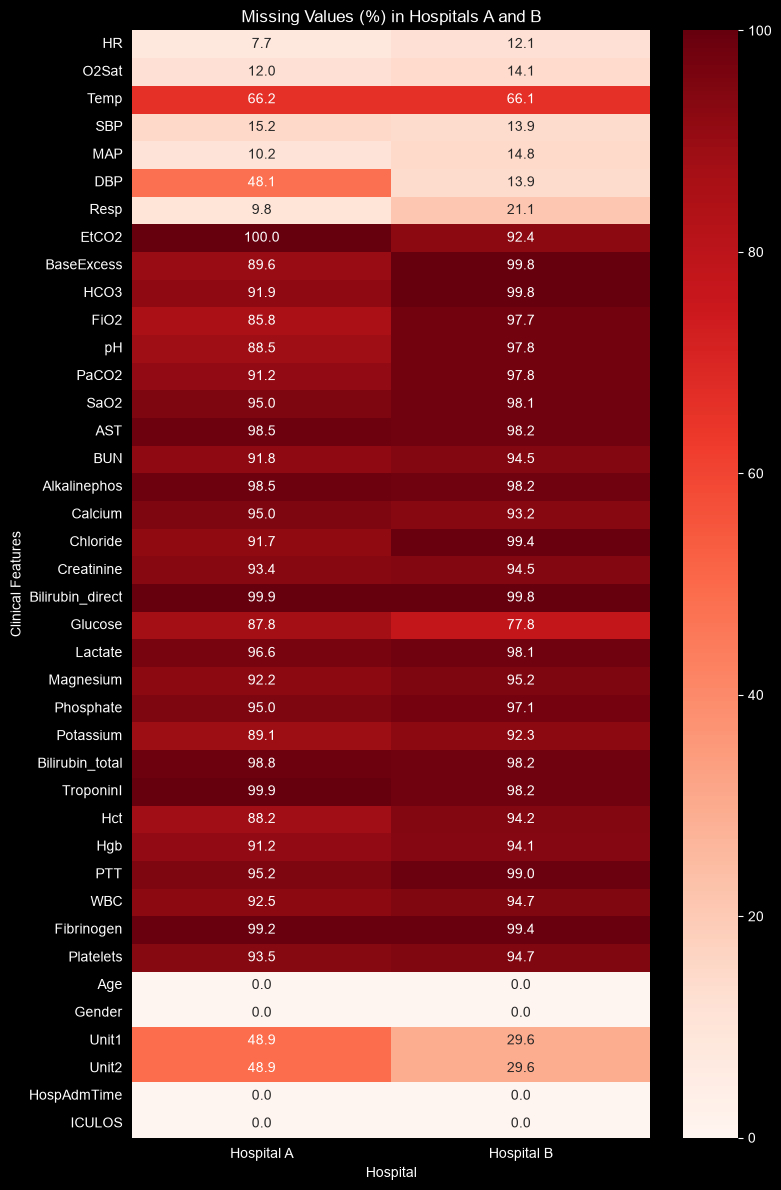

In [6]:
import seaborn as sns

missing_data = pd.DataFrame({
    "Hospital A": missing_A,
    "Hospital B": missing_B
})

# Exclude the target variable
missing_data = missing_data.drop("SepsisLabel")

plt.figure(figsize=(8, 12))

sns.heatmap(
    missing_data,
    annot=True,
    fmt=".1f",
    cmap="Reds",
    vmin=0,
    vmax=100
)

plt.title("Missing Values (%) in Hospitals A and B")
plt.xlabel("Hospital")
plt.ylabel("Clinical Features")

plt.tight_layout()
plt.show()

This is a heatmap showing the percentages of missing values in each hospital. We can see that most laboratory measures, like Bilirubin_total, TroponinI, Lactate, etc., have missing value percentages at almost 90% or higher. On the other hand, vital signs have fewer missing values except for temperature which is missing in around 66% of observations.

One good thing is that the missingness percentages follow almost the same pattern in Hospitals A and B. However, there are some differences, such as DBP, which has 48.1% missing values in Hospital A compared to only 13.9% in Hospital B

One question is: If a person has sepsis, would that person have fewer missing values because laboratory tests are asked to be taken when a person shows signs of sepsis? If this is the case, missingness itself could provide useful information for predicting sepsis.

Another question is: Do different hospitals have different protocols for such cases? This can make missingness an issue because lab values being present may be highly dependent on hospital protocols. This could affect how well a model trained on Hospital A performs on Hospital B, especially if the model learns patterns related to how frequently measurements are taken.

Therefore, it would be interesting to compare missingness between septic and non-septic patients and investigate whether these differences appear before sepsis onset. Also, having a high percentage of missing values does not necessarily mean that a feature is not useful for predicting sepsis.

In [7]:
#Analyze missingness
def missingness_by_sepsis(folder):
    septic_data = []
    non_septic_data = []

    for file in Path(folder).glob("*.psv"):
        df = pd.read_csv(file, sep="|")

        if df["SepsisLabel"].max() == 1:
            septic_data.append(df)
        else:
            non_septic_data.append(df)

    septic = pd.concat(septic_data)
    non_septic = pd.concat(non_septic_data)

    missing_septic = septic.isna().mean() * 100
    missing_non_septic = non_septic.isna().mean() * 100

    return missing_septic, missing_non_septic

In [8]:
missing_septic_A, missing_non_septic_A = missingness_by_sepsis(
    r"C:\Users\bJawh\PycharmProjects\Intro2ML_Project\sepsis_dataset\training_setA"
)
missing_septic_B, missing_non_septic_B = missingness_by_sepsis(
    r"C:\Users\bJawh\PycharmProjects\Intro2ML_Project\sepsis_dataset\training_setB"
)

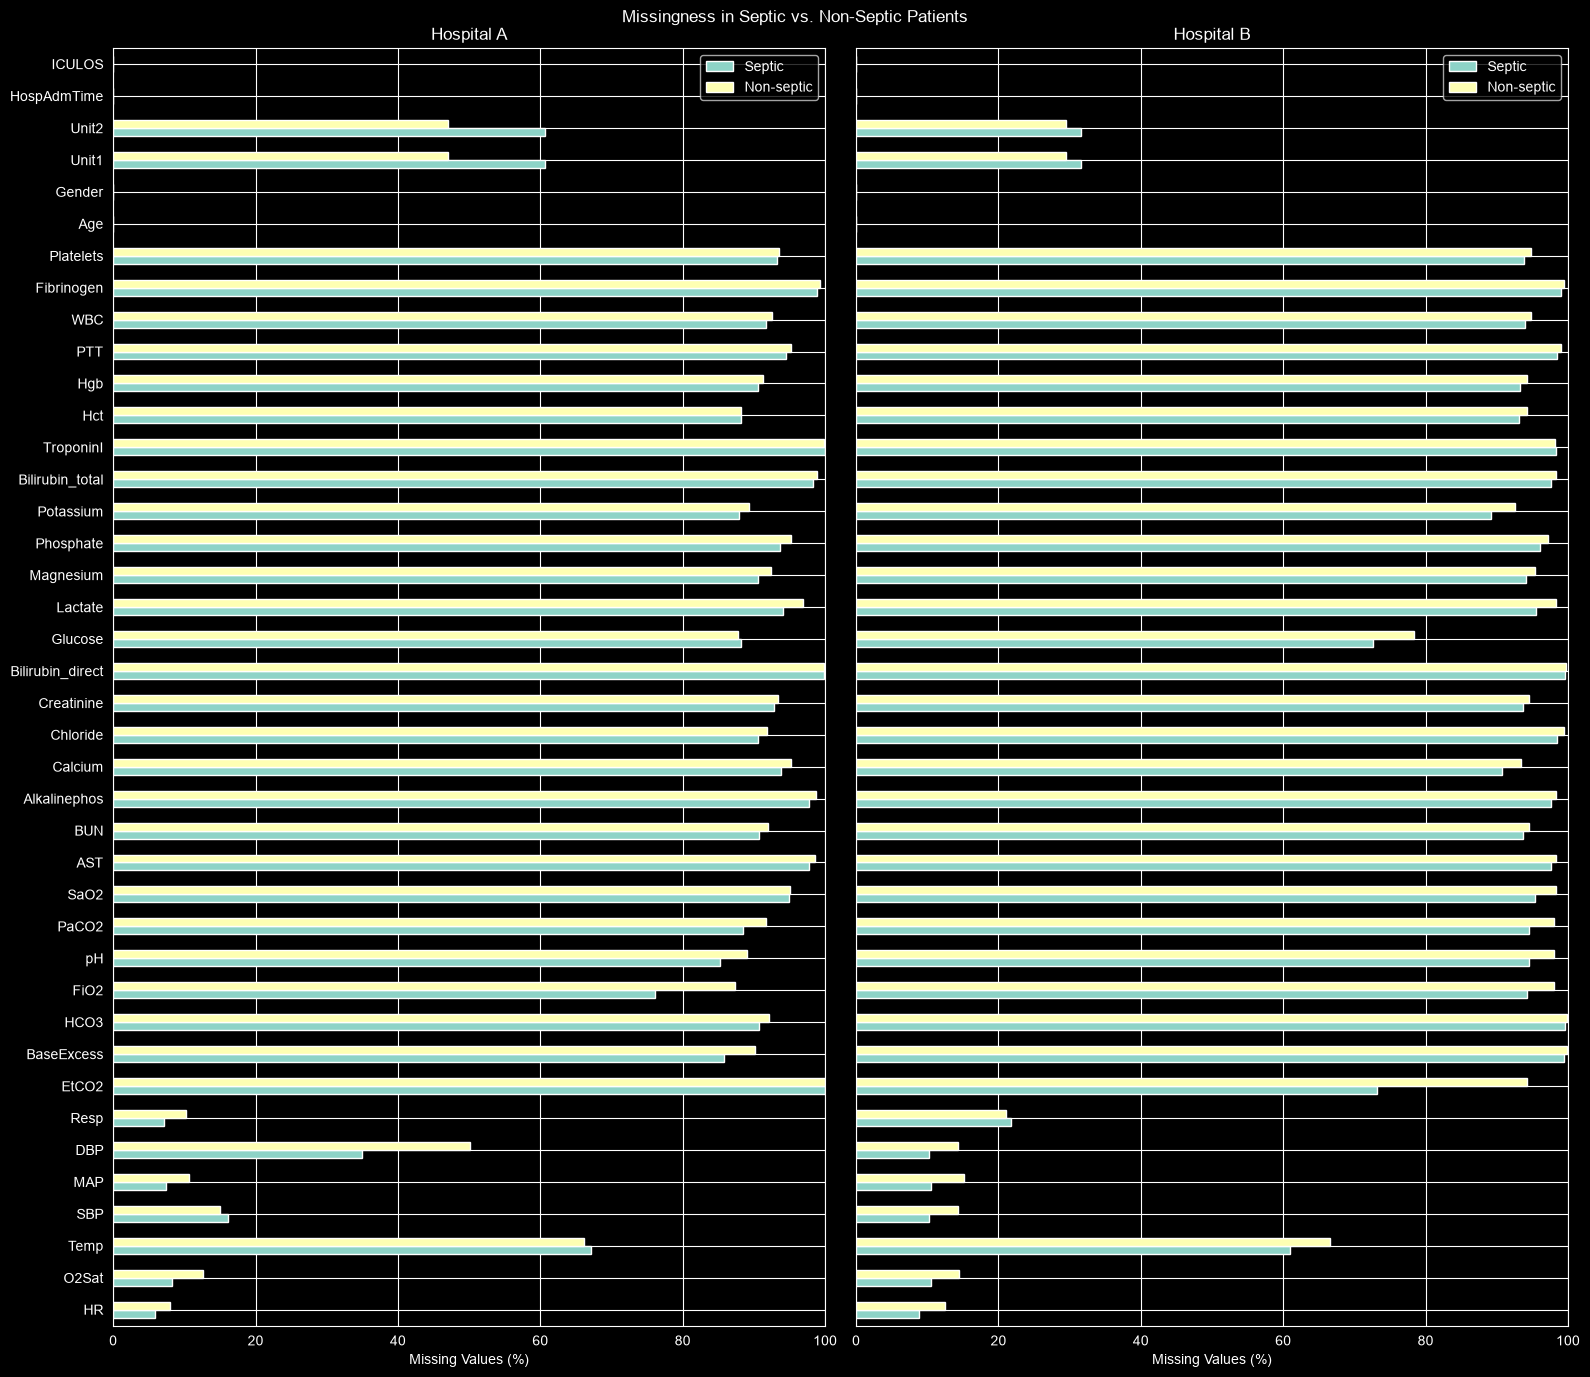

In [9]:
comparison_A = pd.DataFrame({
    "Septic": missing_septic_A,
    "Non-septic": missing_non_septic_A
}).drop("SepsisLabel")

comparison_B = pd.DataFrame({
    "Septic": missing_septic_B,
    "Non-septic": missing_non_septic_B
}).drop("SepsisLabel")

fig, axes = plt.subplots(1, 2, figsize=(16, 14), sharey=True)

comparison_A.plot(kind="barh", ax=axes[0])
comparison_B.plot(kind="barh", ax=axes[1])

axes[0].set_title("Hospital A")
axes[1].set_title("Hospital B")

for ax in axes:
    ax.set_xlabel("Missing Values (%)")
    ax.set_xlim(0, 100)
    ax.legend()

plt.suptitle("Missingness in Septic vs. Non-Septic Patients")
plt.tight_layout()
plt.show()

From Hospital A, we can see that, in fact, missingness is slightly affected by whether a person develops sepsis or not. Specifically, almost all lab values are present more frequently when a person develops sepsis, with some exceptions, such as lactate. However, missingness in these values is still very high for both groups across almost all laboratory measurements.

One thing that is noticeable is that patients who do not develop sepsis have the unit numbers (Unit1 and Unit2) present more frequently. Could that be a coincidence? One possible explanation is that patients are assigned to different ICU units depending on their clinical conditions. However this does not explain why the unit information itself is missing more frequently among septic patients. We also see that patients who develop sepsis have their blood pressures taken more often, particularly MAP and DBP.

We observe almost the same pattern in Hospital B, with some differences. In Hospital B, we can see that EtCO2 is measured much more frequently when a person develops sepsis than when a person does not. However, in Hospital A, this measurement is not taken at all. This means that we would need to remove this feature from our main model, since we are training on Hospital A and testing on Hospital B. However, this could lead to the loss of a potentially valuable feature, especially since its availability seems to be related to sepsis status in Hospital B.

The missingness patterns are generally similar across both hospitals, with some noticeable differences, particularly EtCO2. Therefore, although hospital practices might affect the availability of certain measurements, the results do not provide enough evidence to conclude that missingness is strongly dependent on hospital protocols


### All features, both hospitals

From here on, every analysis uses the two data frames `df_A` and `df_B`, which are loaded **once** in the next cell (the earlier version re-read all 40,000 `.psv` files in almost every cell). Each analysis now covers **all features of both hospitals**:

- **Vital signs (8), laboratory values (26) and demographic/administrative variables (6)** are plotted as separate figures for each hospital, so that every panel stays readable. Binary variables (Gender, Unit1, Unit2) are shown as bars, the others as boxplots.
- The analyses over time (values, measurement frequency and variability before sepsis onset, patient timelines) use the **34 vital/lab measurements**. Age, Gender, Unit1, Unit2 and HospAdmTime do not change during a stay and ICULOS is the time axis itself, so these static variables are covered in the distribution, correlation and availability analyses instead.
- Sepsis onset = first positive `SepsisLabel` + 6 hours (the label switches on 6 hours before onset), as in the earlier cells.
- A panel that says *no data* means the feature is completely missing for that group (for example EtCO2 in Hospital A).

In [10]:
# Load BOTH hospitals once. Every analysis below re-uses df_A and df_B.
import numpy as np
import seaborn as sns
from math import ceil

DATA_DIRS = {
    "Hospital A": r"C:\Users\bJawh\PycharmProjects\Intro2ML_Project\sepsis_dataset\training_setA",
    "Hospital B": r"C:\Users\bJawh\PycharmProjects\Intro2ML_Project\sepsis_dataset\training_setB",
}

# The 40 features of the PhysioNet/CinC 2019 files, split into their clinical groups
VITALS = ["HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp", "EtCO2"]

LABS = ["BaseExcess", "HCO3", "FiO2", "pH", "PaCO2", "SaO2",
        "AST", "BUN", "Alkalinephos", "Calcium", "Chloride",
        "Creatinine", "Bilirubin_direct", "Glucose", "Lactate",
        "Magnesium", "Phosphate", "Potassium", "Bilirubin_total",
        "TroponinI", "Hct", "Hgb", "PTT", "WBC",
        "Fibrinogen", "Platelets"]

DEMOGRAPHICS = ["Age", "Gender", "Unit1", "Unit2", "HospAdmTime", "ICULOS"]

CLINICAL = VITALS + LABS                 # the 34 measurements that change over time
ALL_FEATURES = CLINICAL + DEMOGRAPHICS   # all 40 features
BINARY = ["Gender", "Unit1", "Unit2"]    # 0/1 variables (drawn as bars instead of boxplots)

FEATURE_GROUPS = {
    "Vital signs": VITALS,
    "Laboratory values": LABS,
    "Demographic / administrative": DEMOGRAPHICS,
}


def load_hospital(folder):
    """Read every .psv file of one hospital into ONE DataFrame (one row per patient-hour)."""
    frames = []
    for patient_id, file in enumerate(sorted(Path(folder).glob("*.psv"))):
        df = pd.read_csv(file, sep="|", dtype=np.float32)
        df.insert(0, "PatientID", np.int32(patient_id))
        df.insert(1, "Hour", np.arange(len(df), dtype=np.int32))   # row number within the stay: 0, 1, 2, ...
        frames.append(df)
    data = pd.concat(frames, ignore_index=True)

    not_found = set(ALL_FEATURES + ["SepsisLabel"]) - set(data.columns)
    if not_found:
        raise ValueError(f"Columns not found in {folder}: {sorted(not_found)}")

    # Sepsis information per patient, added to every row
    first_positive = data.loc[data["SepsisLabel"] == 1].groupby("PatientID")["Hour"].min()
    data["Septic"] = data["PatientID"].isin(first_positive.index)
    data["OnsetHour"] = data["PatientID"].map(first_positive) + 6        # NaN for non-septic patients
    data["HoursToOnset"] = data["Hour"] - data["OnsetHour"]              # 0 = onset, -6 = first positive label

    data["PatientStatus"] = pd.Categorical(np.where(data["Septic"], "Septic", "Non-septic"),
                                           categories=["Non-septic", "Septic"])
    phase = np.where(~data["Septic"], "Non-septic",
                     np.where(data["HoursToOnset"] >= 0, "Sepsis", "Pre-sepsis"))
    data["Phase"] = pd.Categorical(phase, categories=["Non-septic", "Pre-sepsis", "Sepsis"])
    return data


df_A = load_hospital(DATA_DIRS["Hospital A"])
df_B = load_hospital(DATA_DIRS["Hospital B"])
HOSPITALS = {"Hospital A": df_A, "Hospital B": df_B}

# Quick check: these numbers should match the summary printed earlier in the notebook
for name, df in HOSPITALS.items():
    n_septic = int(df.groupby("PatientID")["Septic"].first().sum())
    print(f"{name}: {df['PatientID'].nunique():,} patients ({n_septic:,} septic), "
          f"{len(df):,} hourly rows, {df.memory_usage(deep=True).sum() / 1e6:.0f} MB in memory")

Hospital A: 20,336 patients (1,790 septic), 790,215 hourly rows, 151 MB in memory
Hospital B: 20,000 patients (1,142 septic), 761,995 hourly rows, 146 MB in memory


In [11]:
# Helper functions used by the analyses below
COLORS = {"Hospital A": "#4c78a8", "Hospital B": "#f58518",
          "Non-septic": "#9ecae1", "Septic": "#e6550d",
          "Pre-sepsis": "#fdae6b", "Sepsis": "#e6550d"}

GROUP_NCOLS = {"Vital signs": 4, "Laboratory values": 6, "Demographic / administrative": 3}


def new_grid(n_panels, ncols, cell=(3.3, 2.7), **kwargs):
    """A grid of subplots with room for n_panels panels (unused panels are hidden)."""
    nrows = ceil(n_panels / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * cell[0], nrows * cell[1]), **kwargs)
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[n_panels:]:
        ax.set_visible(False)
    return fig, axes[:n_panels]


def show_no_data(ax, message="no data"):
    ax.text(0.5, 0.5, message, ha="center", va="center", transform=ax.transAxes, color="gray", fontsize=8)
    ax.set_xticks([])
    ax.set_yticks([])


def compare_features(selections, features, ncols):
    """One panel per feature. selections = [(label, dataframe, row_mask or None), ...]
    Continuous features: one boxplot per selection (outliers hidden). Binary features: % of rows equal to 1."""
    fig, axes = new_grid(len(features), ncols)
    labels = [label for label, _, _ in selections]

    for ax, feature in zip(axes, features):
        values = []
        for _, df, mask in selections:
            v = df[feature].to_numpy()
            v = v if mask is None else v[mask]
            values.append(v[~np.isnan(v)])

        if all(len(v) == 0 for v in values):
            show_no_data(ax)
        elif feature in BINARY:
            ax.bar(labels, [v.mean() * 100 if len(v) else np.nan for v in values],
                   color=[COLORS[label] for label in labels])
            ax.set_ylim(0, 100)
            ax.set_ylabel("% of rows = 1", fontsize=8)
        else:
            positions = [i + 1 for i, v in enumerate(values) if len(v)]
            boxes = ax.boxplot([v for v in values if len(v)], positions=positions, widths=0.6,
                               showfliers=False, patch_artist=True, medianprops={"color": "black"})
            for box, position in zip(boxes["boxes"], positions):
                box.set_facecolor(COLORS[labels[position - 1]])
            ax.set_xticks(range(1, len(labels) + 1))
            ax.set_xticklabels(labels, fontsize=8)
            ax.set_xlim(0.4, len(labels) + 0.6)
            ax.set_ylabel("Measured value", fontsize=8)
        ax.set_title(feature)
    return fig


def compare_all_features(selections, title):
    """Vital signs, laboratory values and demographic/administrative variables, one figure each."""
    for group_name, features in FEATURE_GROUPS.items():
        fig = compare_features(selections, features, ncols=GROUP_NCOLS[group_name])
        fig.suptitle(f"{group_name} — {title}", fontsize=13)
        fig.tight_layout(rect=(0, 0, 1, 0.97))
        plt.show()

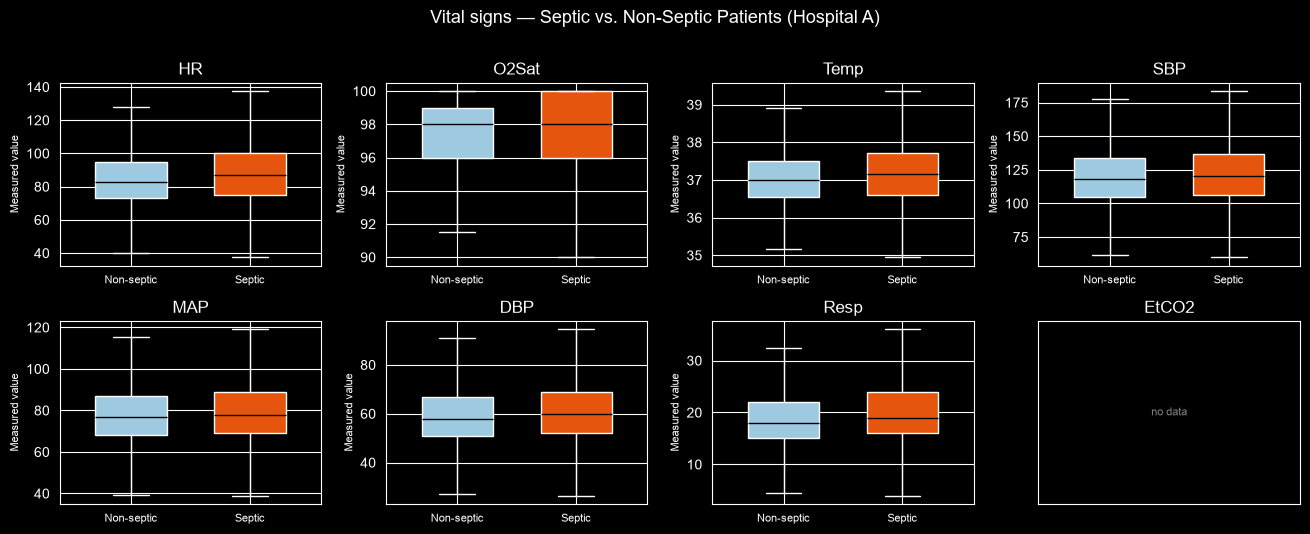

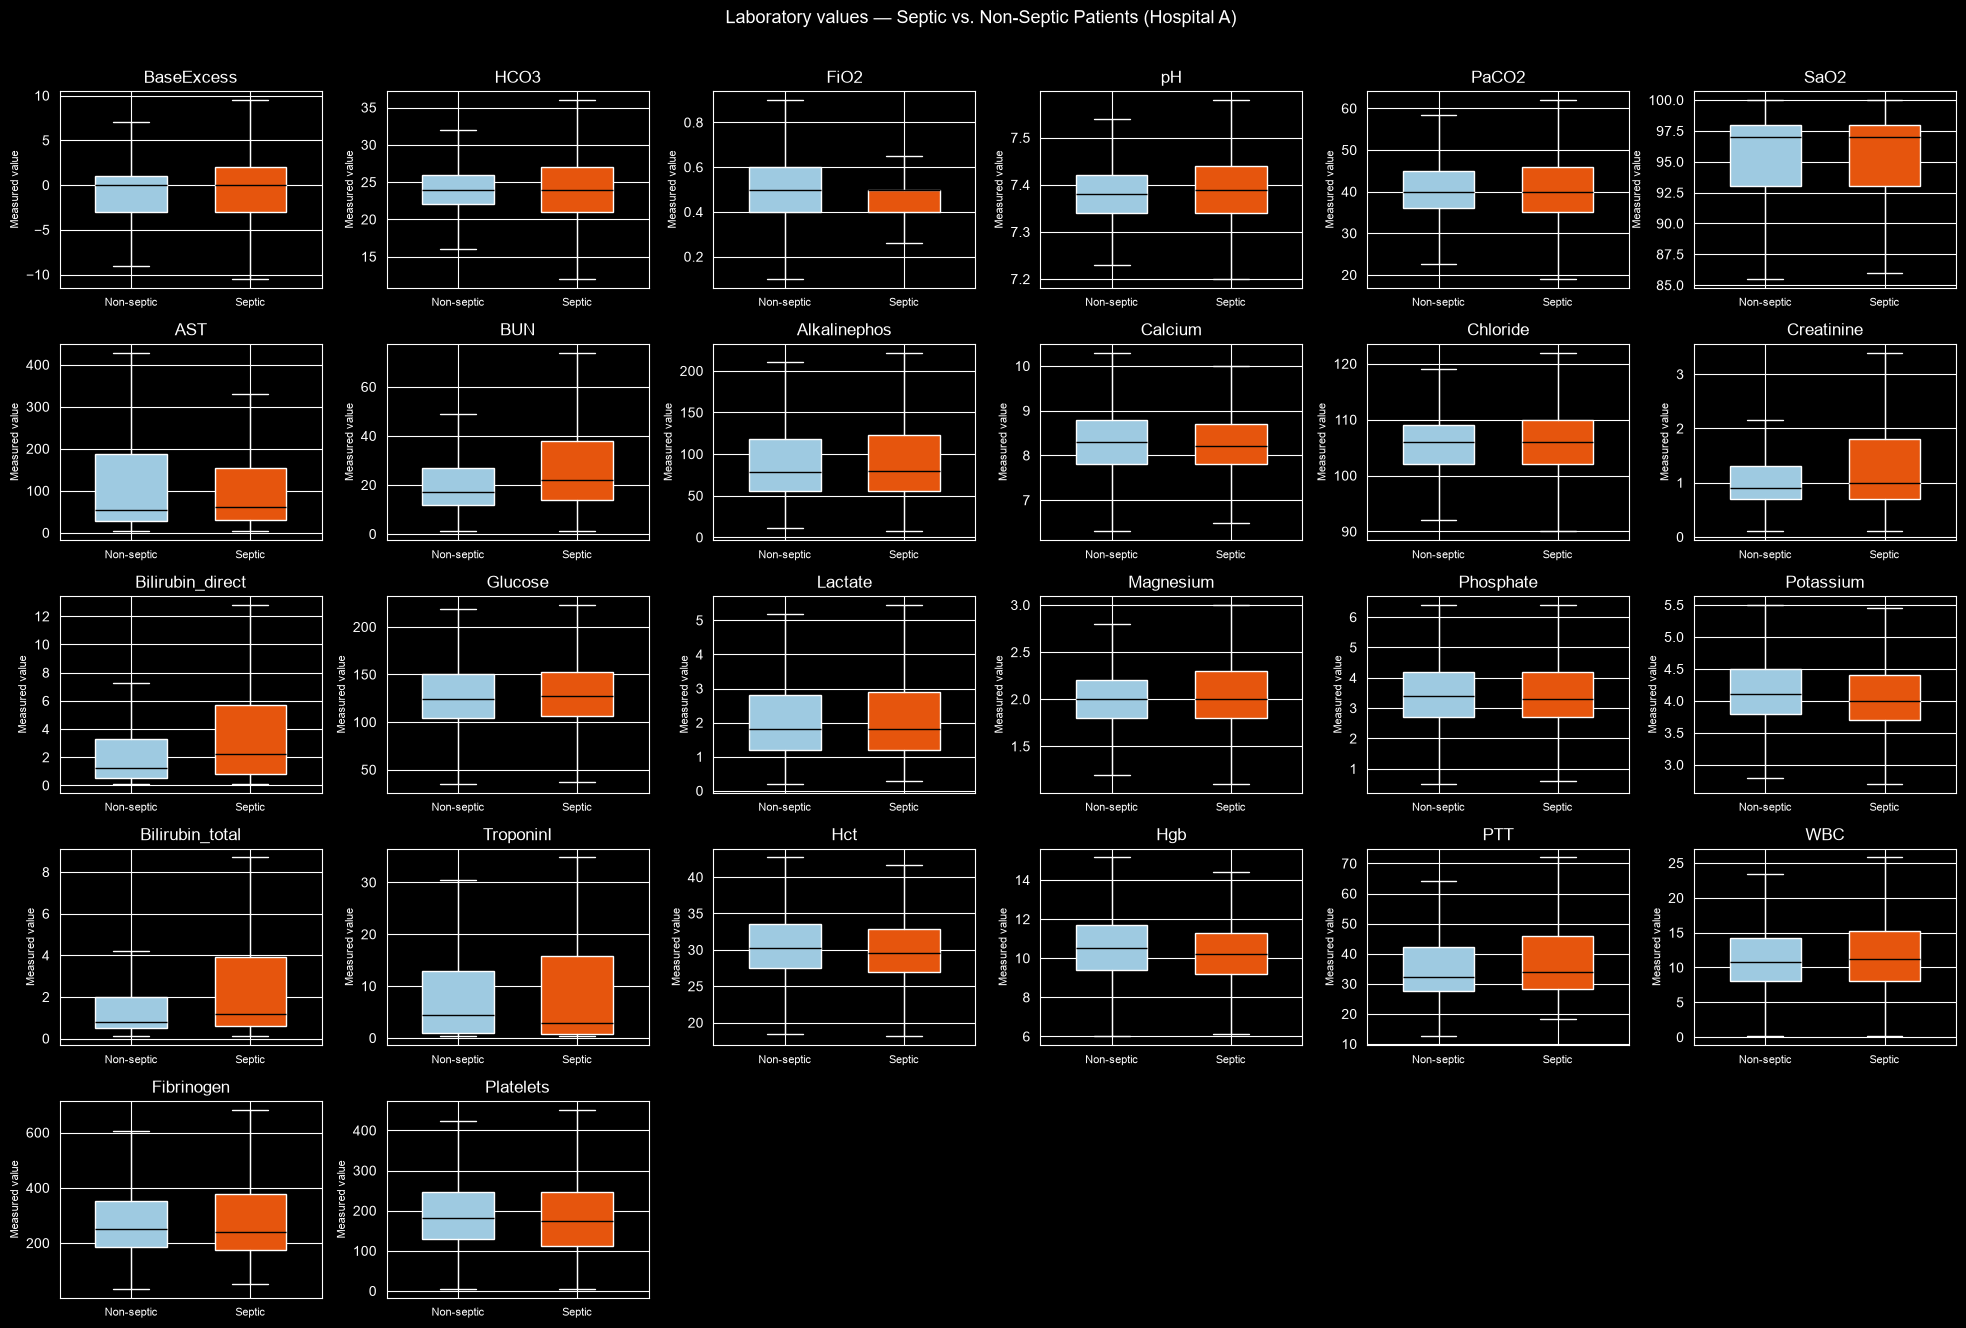

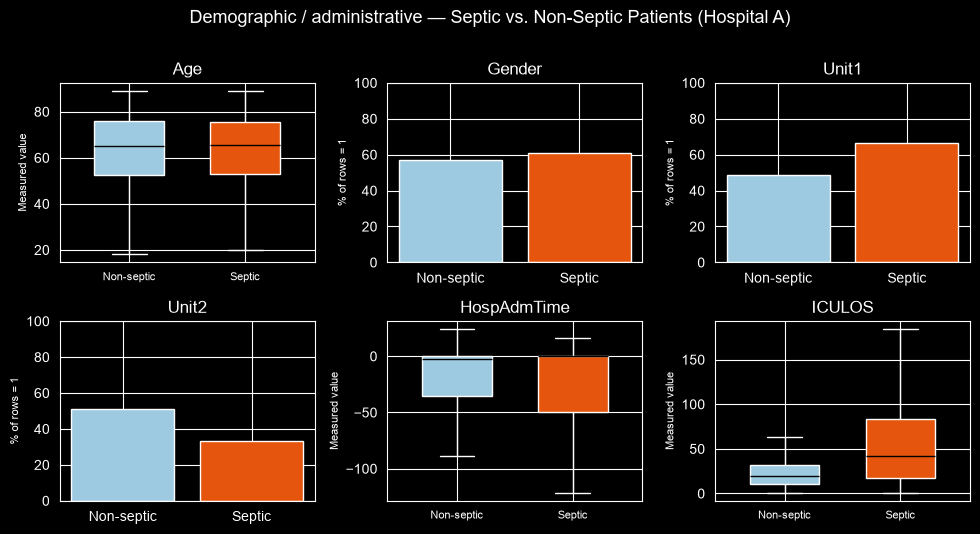

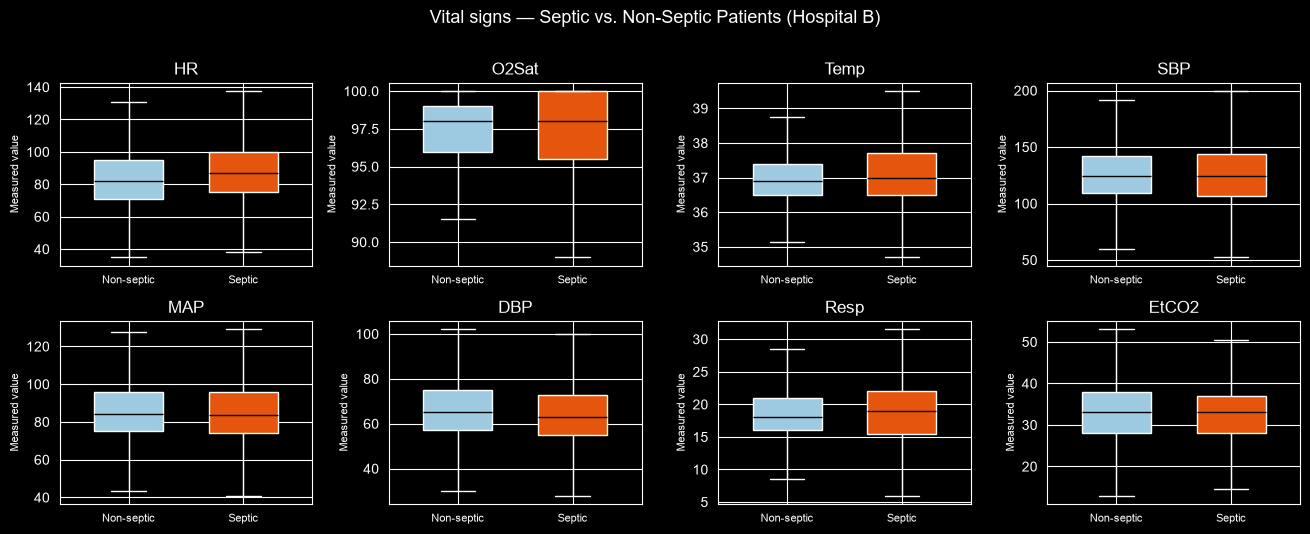

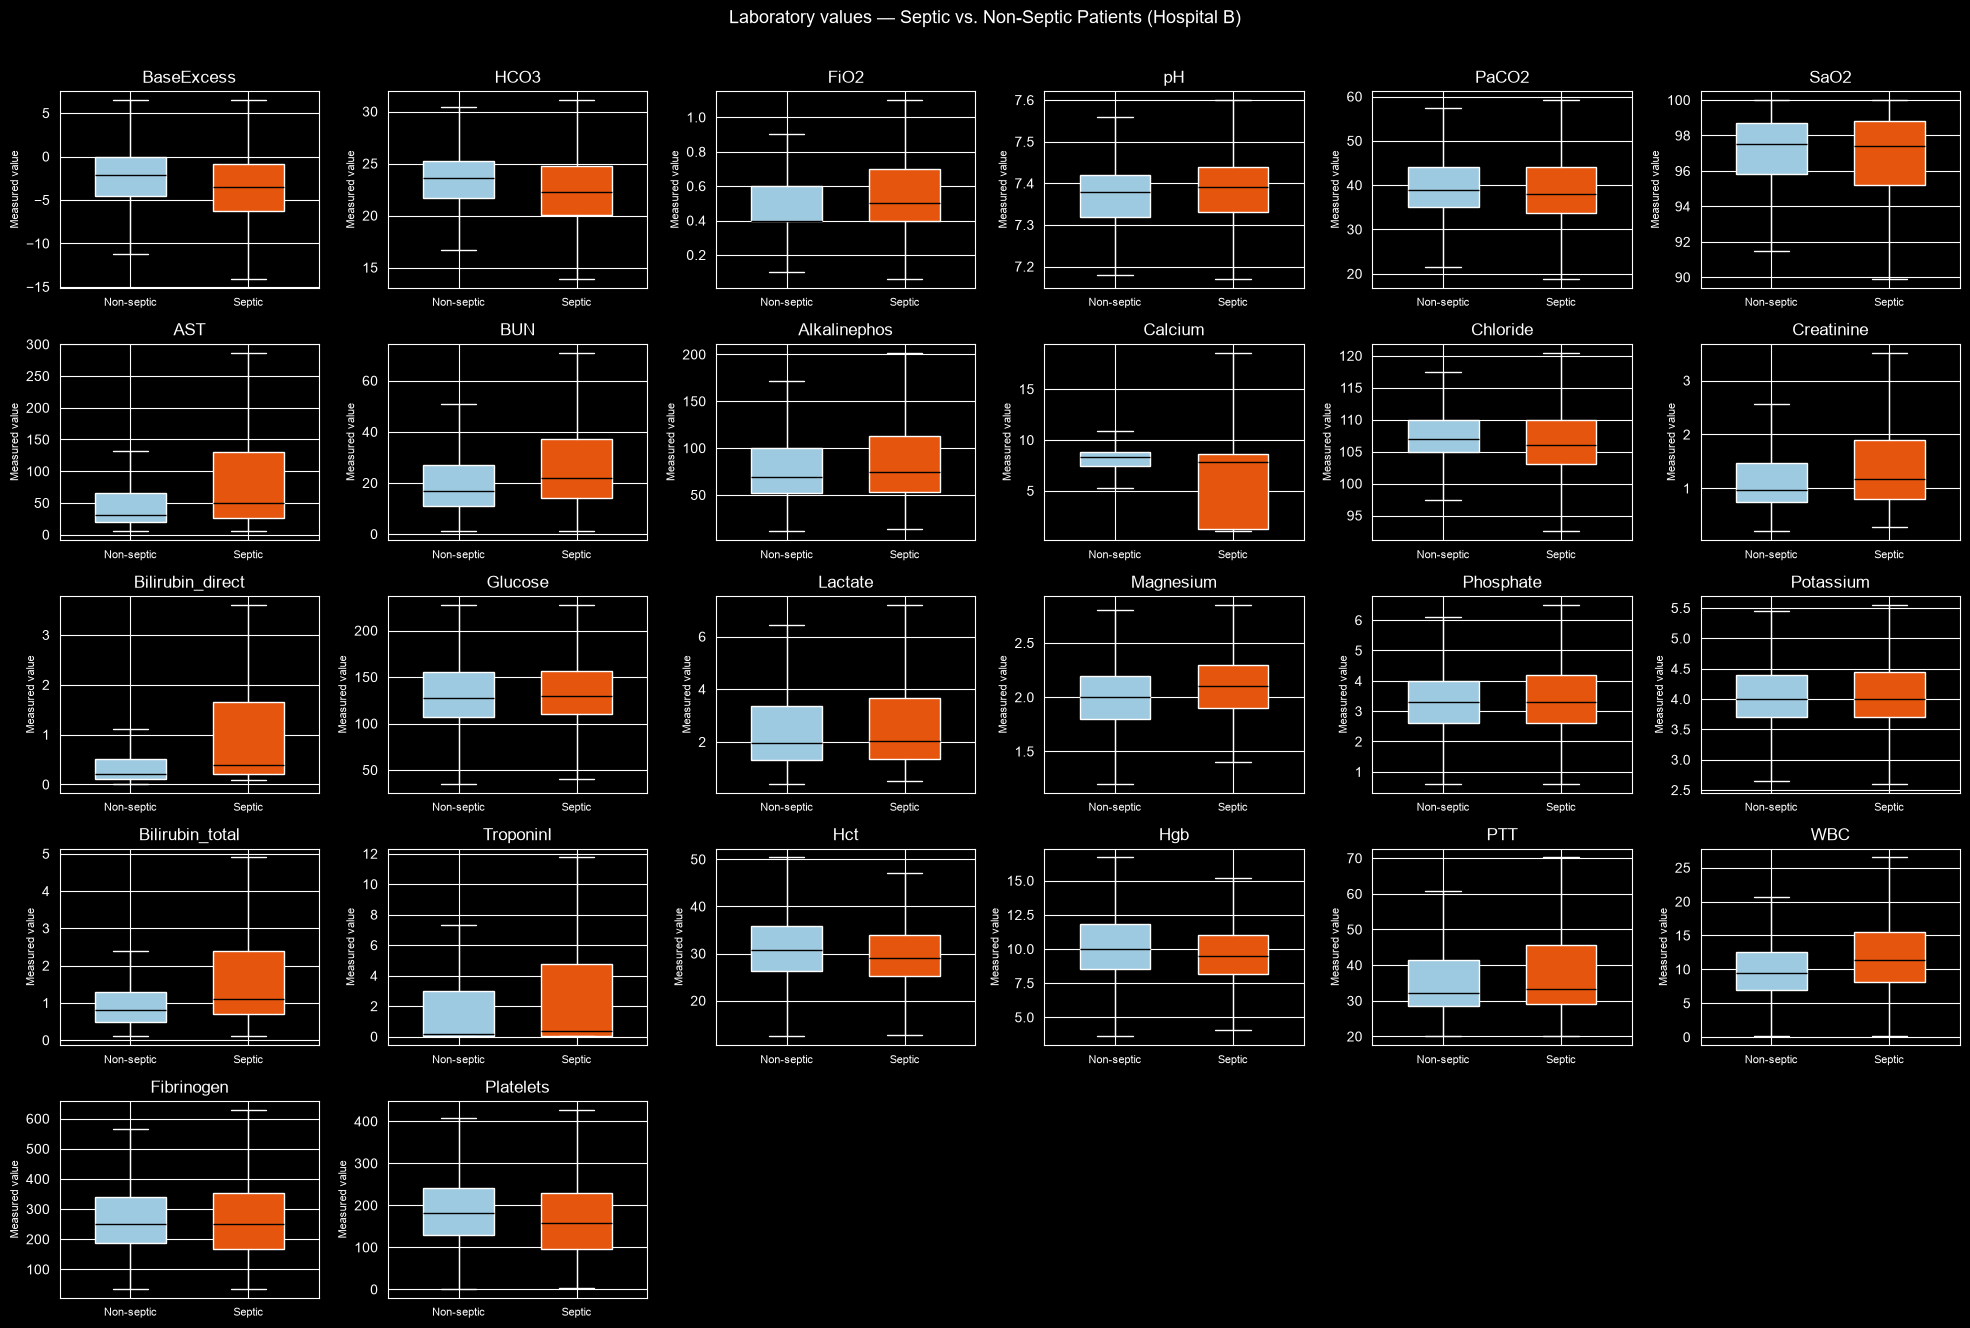

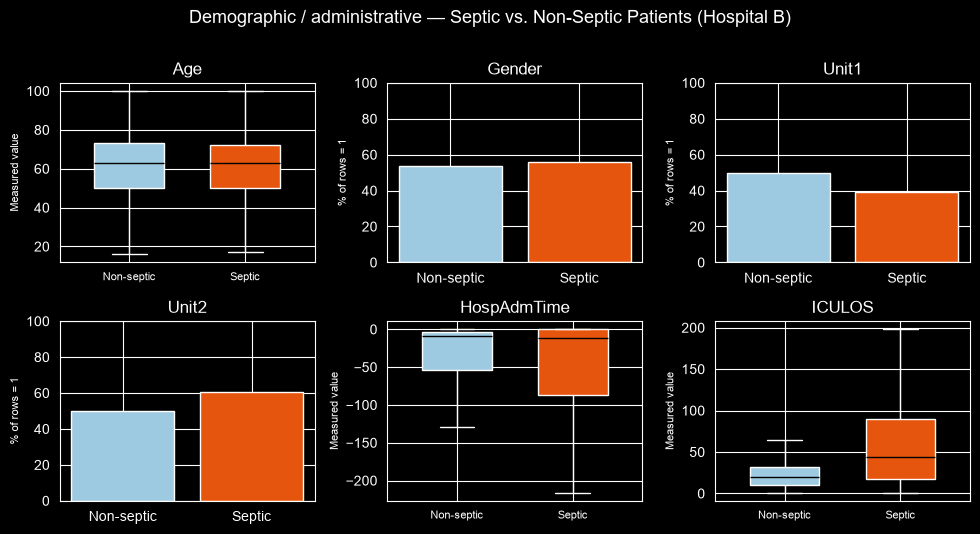

In [12]:
# Septic vs. non-septic patients: ALL features, BOTH hospitals
for hospital, df in HOSPITALS.items():
    selections = [(status, df, (df["PatientStatus"] == status).to_numpy())
                  for status in ["Non-septic", "Septic"]]
    compare_all_features(selections, f"Septic vs. Non-Septic Patients ({hospital})")

Why choose to represent these features specifically?
Heart rate (HR): Sepsis can cause tachycardia (increased heart rate).
Mean arterial pressure (MAP): Sepsis can cause hypotension due to circulatory dysfunction
Respiratory rate (Resp): Increased respiratory rate can be an early sign of physiological deterioration.
Temperature (Temp): Fever or hypothermia can indicate infection.
Lactate: Elevated lactate can indicate impaired tissue perfusion or metabolic stress.
White blood cell count (WBC): Abnormal values can reflect an inflammatory response.
We can see that these are verified. However, here we are finding these values for when sepsis label is 1 as well as before that for septic patients... What if we saw that data only before the patient develops sepsis since our aim is to predict sepsis?

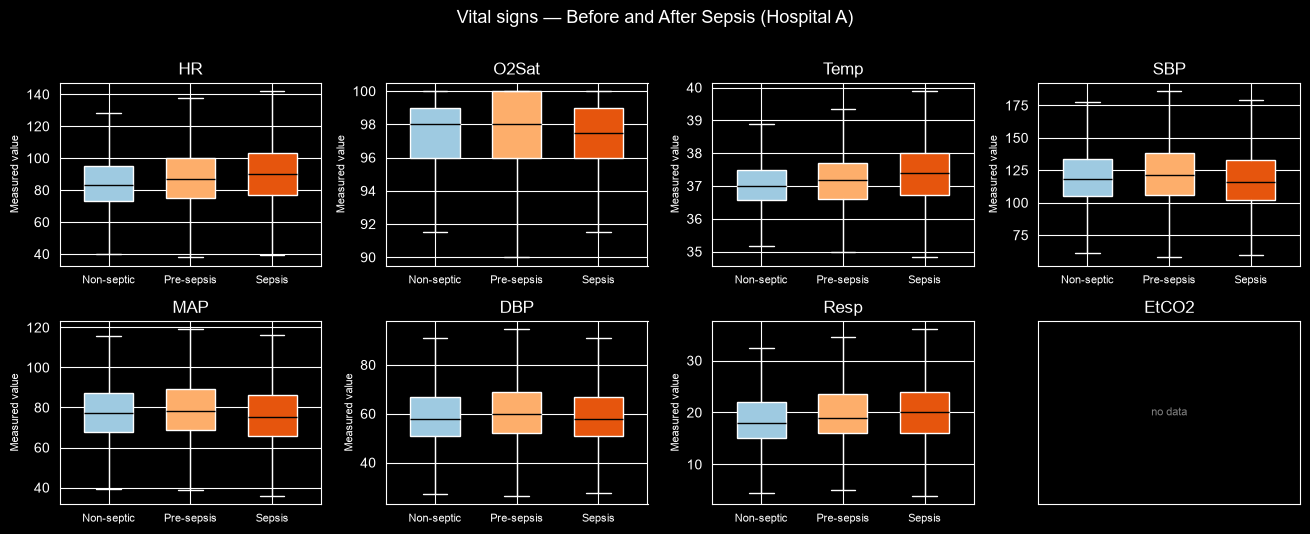

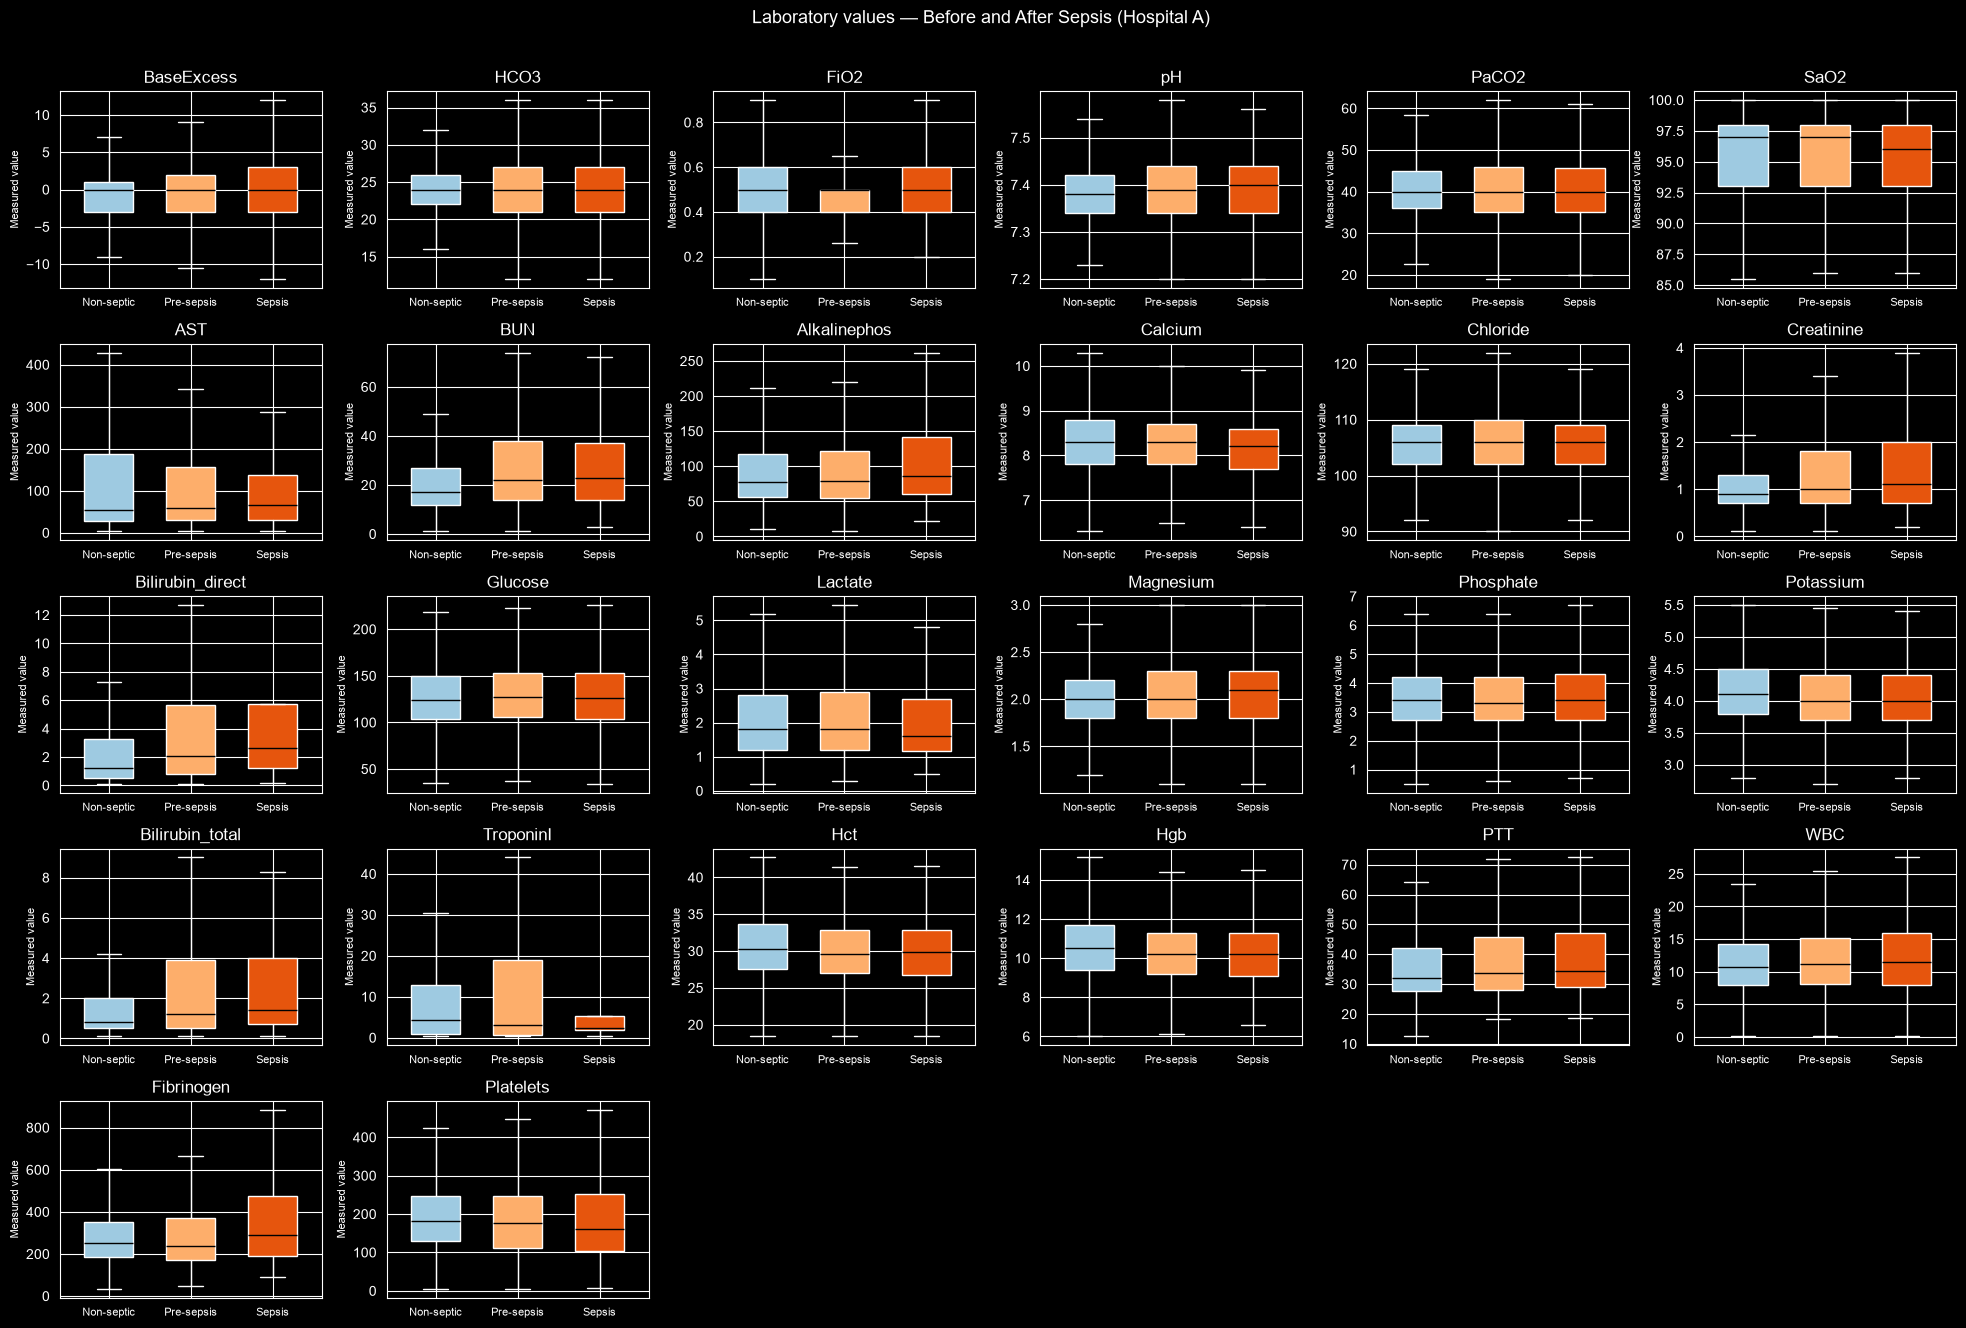

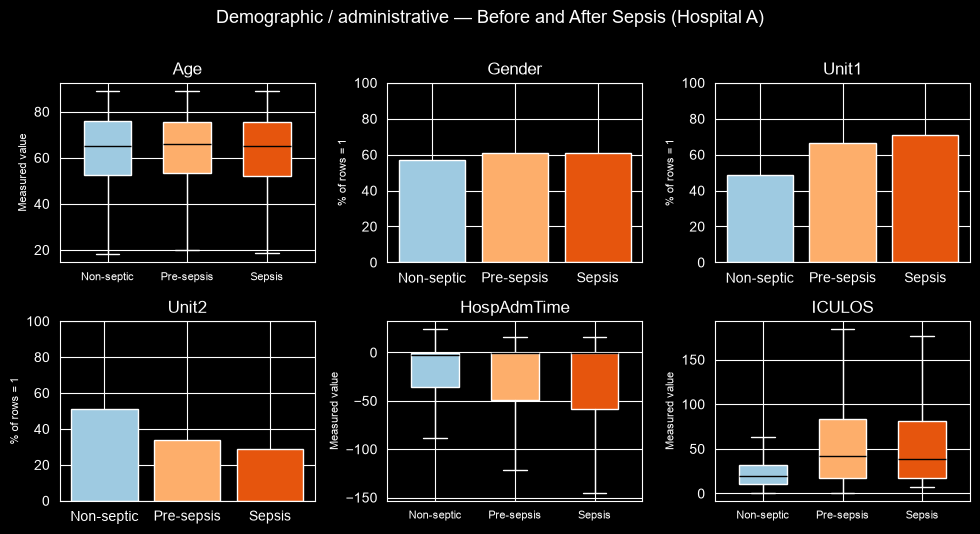

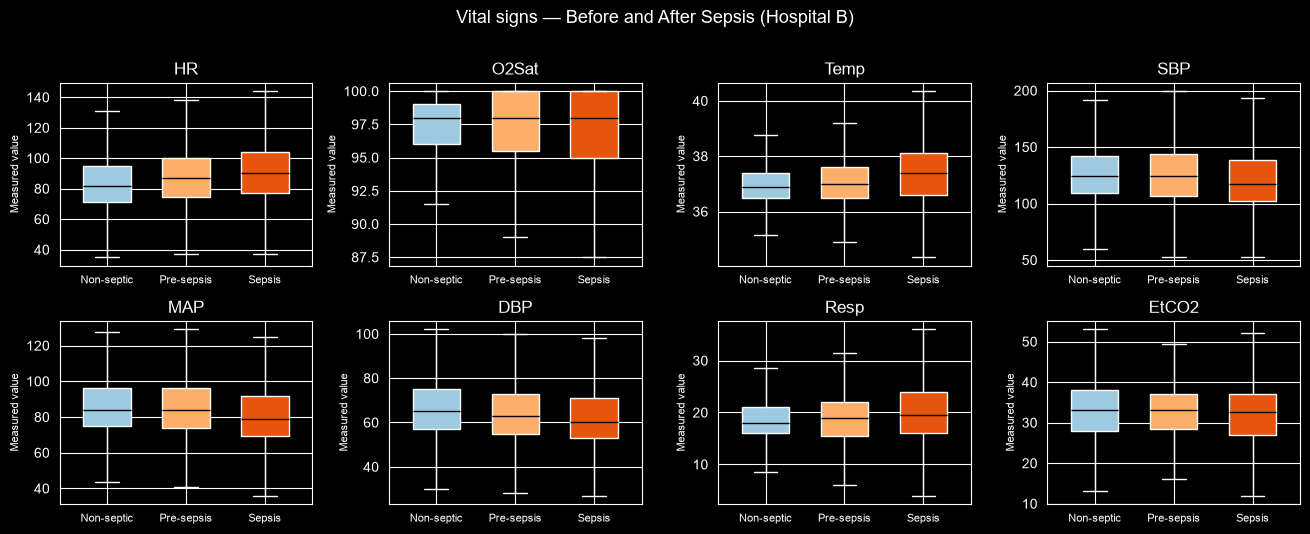

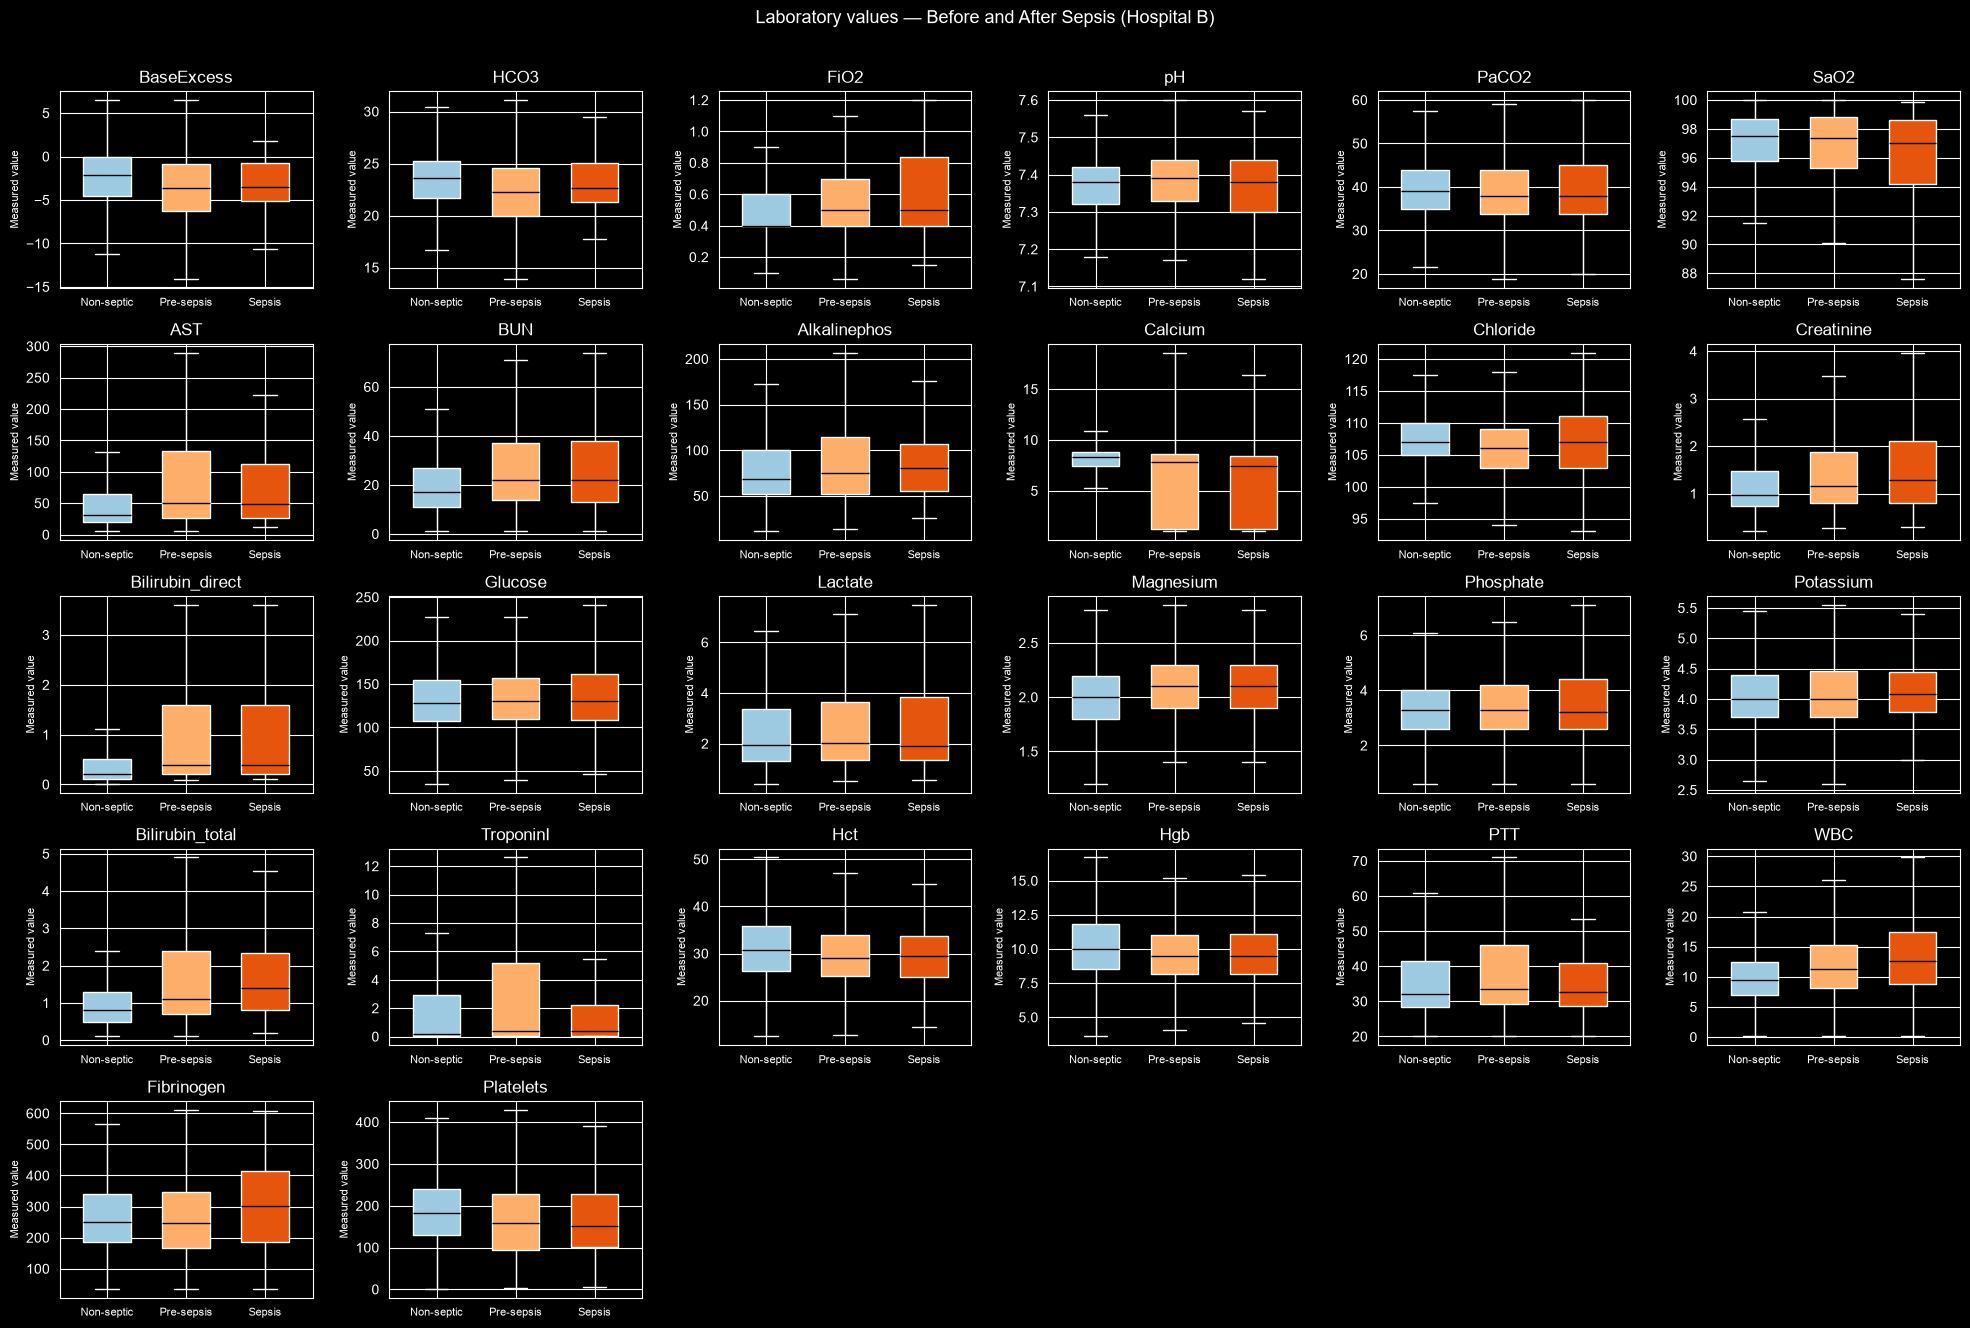

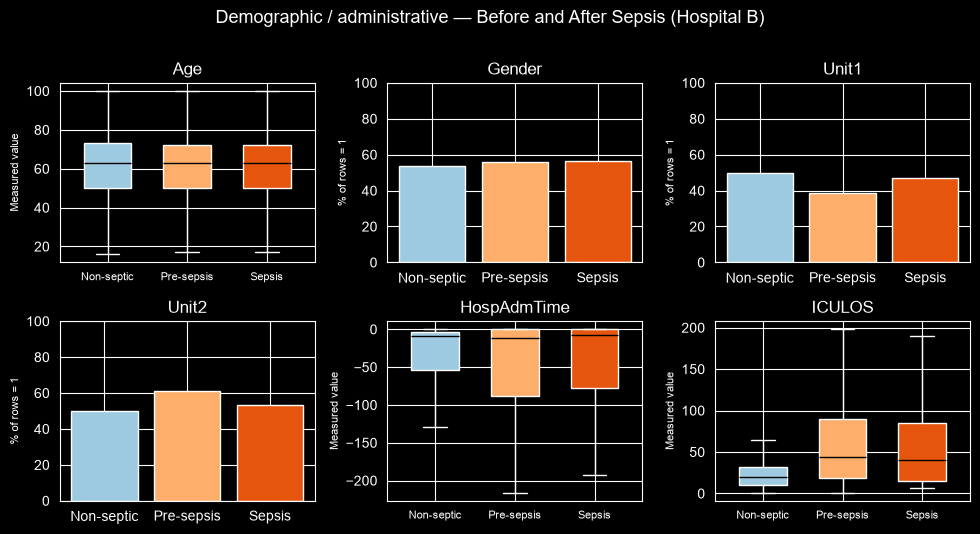

In [13]:
# Comparing features before and after sepsis: ALL features, BOTH hospitals
# Non-septic = patients who never develop sepsis
# Pre-sepsis = rows of septic patients before the onset (onset = first positive label + 6 h)
# Sepsis     = rows of septic patients from the onset on
for hospital, df in HOSPITALS.items():
    selections = [(phase, df, (df["Phase"] == phase).to_numpy())
                  for phase in ["Non-septic", "Pre-sepsis", "Sepsis"]]
    compare_all_features(selections, f"Before and After Sepsis ({hospital})")

We can see that the means and standard deviations do differ pre-sepsis and resemble the sepsis case more that the non-sepsis case... which could mean that these features could help us in predicting sepsis.

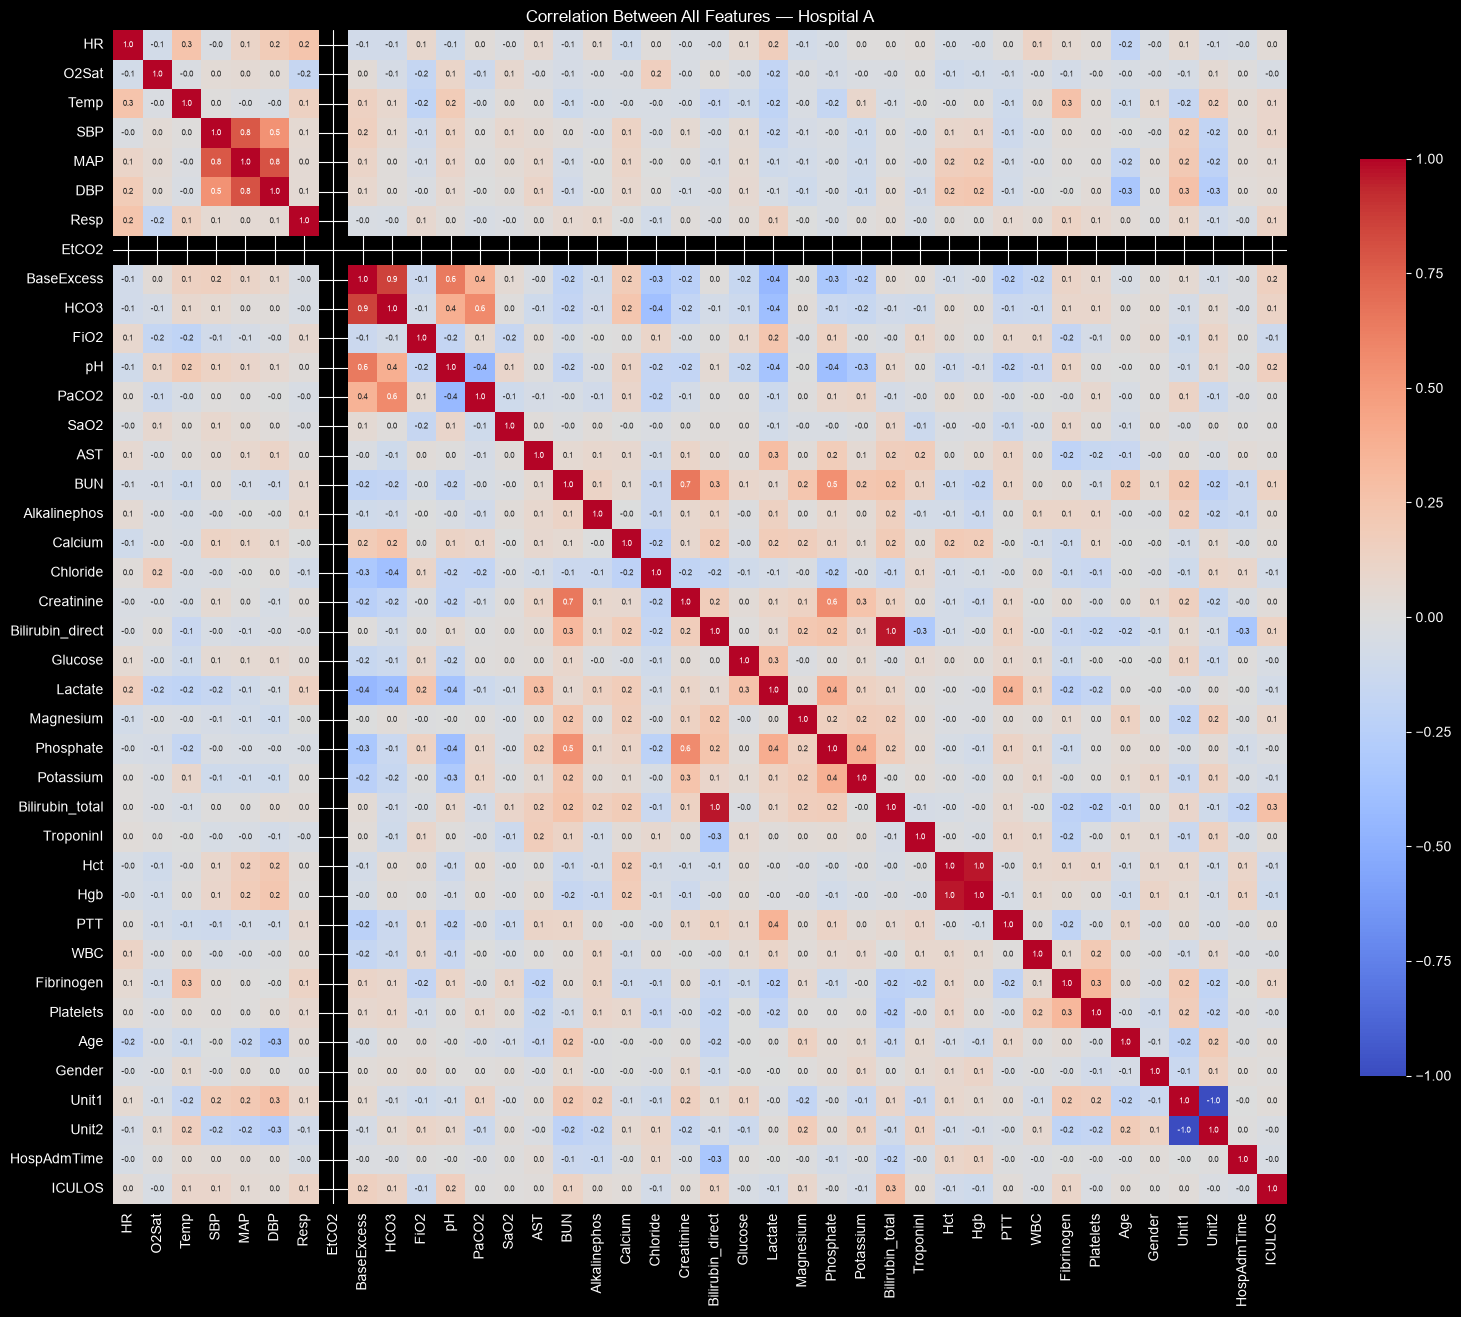

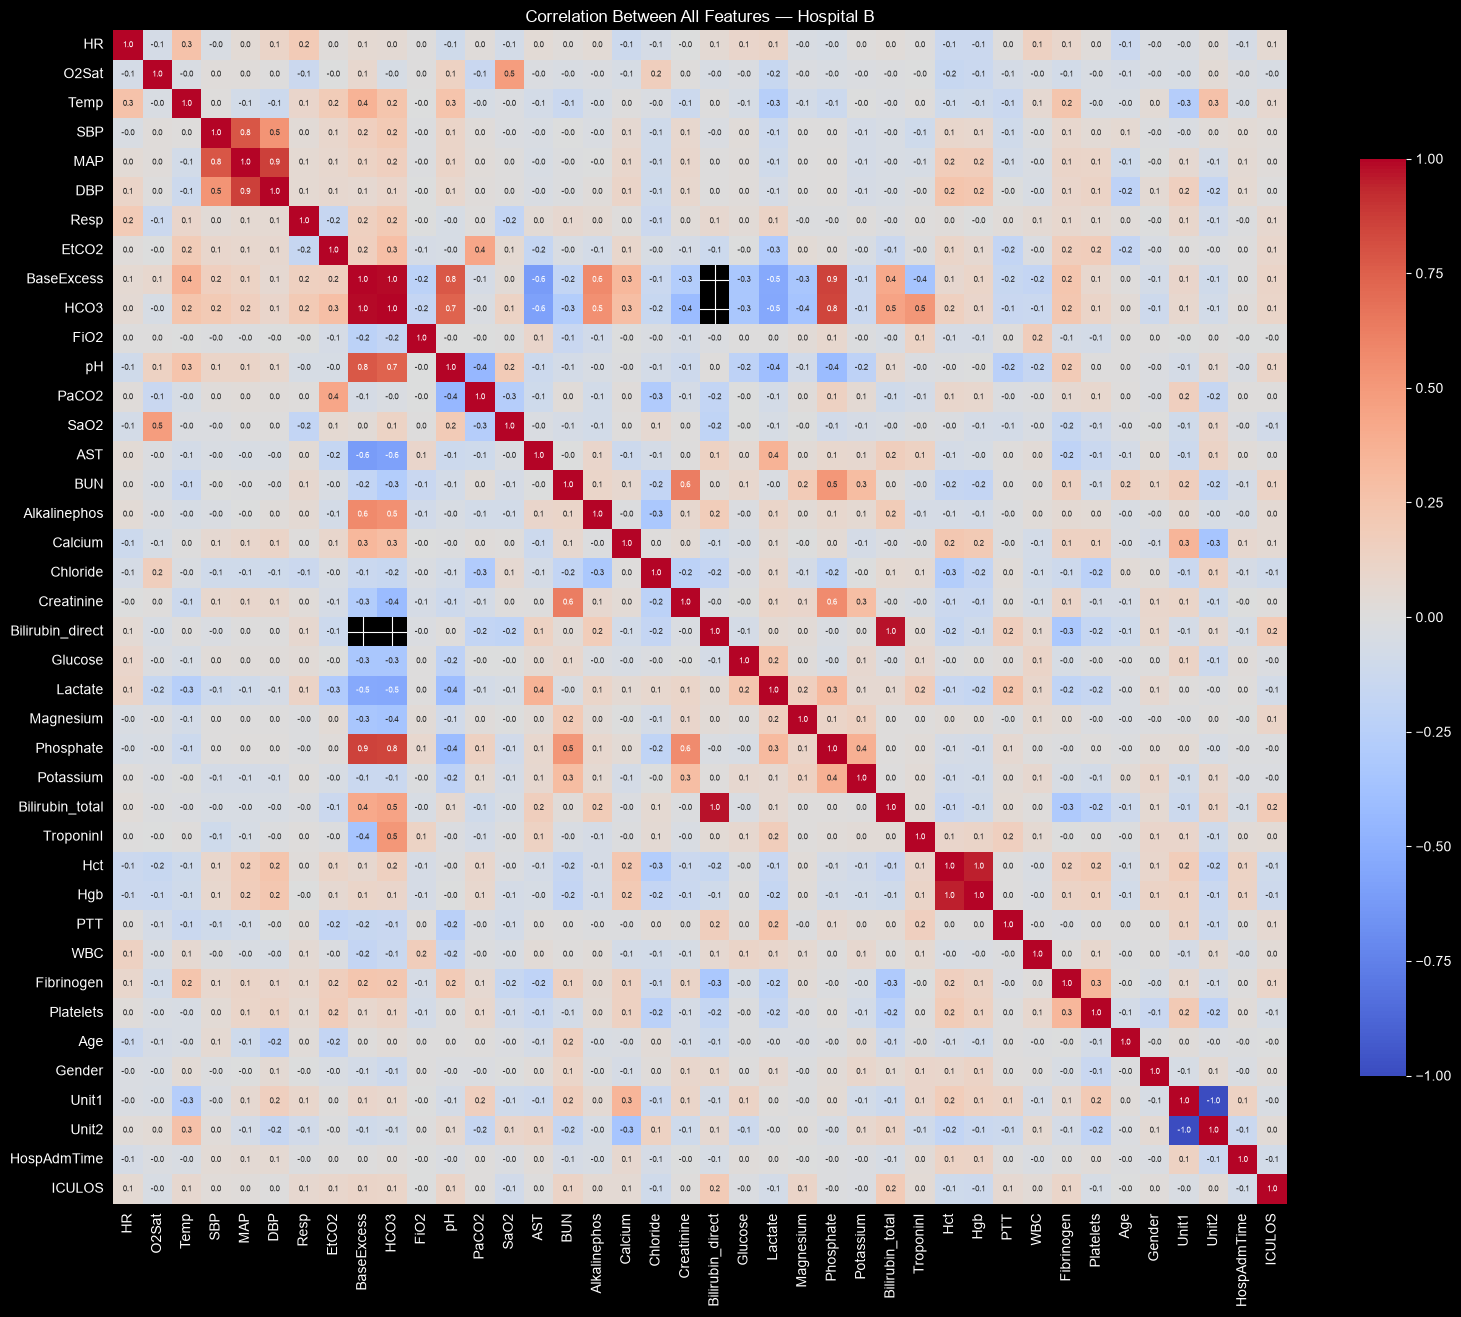

In [14]:
# Correlation between ALL features (vitals, labs and demographics): BOTH hospitals
for hospital, df in HOSPITALS.items():
    correlation = df[ALL_FEATURES].corr()       # pairwise, ignoring missing values

    plt.figure(figsize=(16, 14))
    sns.heatmap(
        correlation,
        annot=True,
        fmt=".1f",
        annot_kws={"size": 6},
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        square=True,
        cbar_kws={"shrink": 0.7}
    )

    plt.title(f"Correlation Between All Features — {hospital}")
    plt.tight_layout()
    plt.show()

Why do we want to see the correlation between features?
Seeing how features are correlated would help us see if any features are repetitive where we can reduce the number of features without losing much predictive value... one very interesting thing would be to show the correlation between features and sepsis.

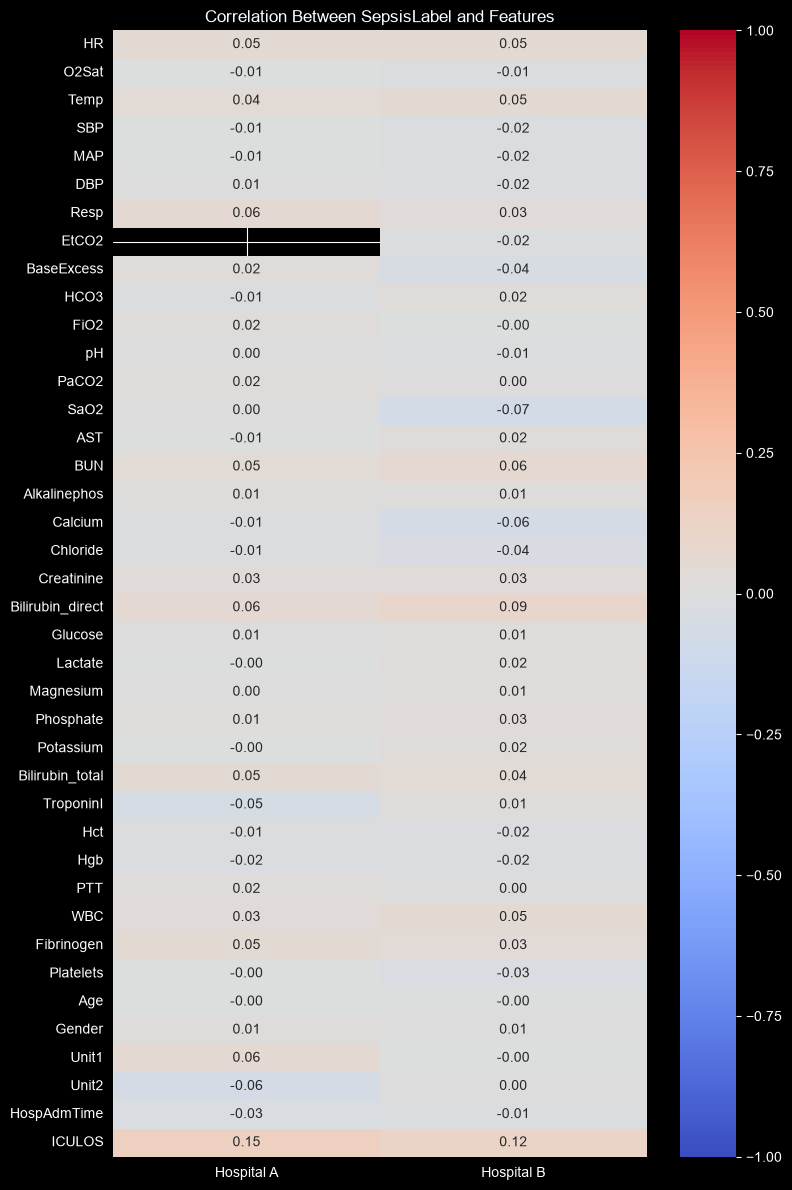

In [15]:
# Correlation between SepsisLabel and all features — Hospitals A and B
comparison = pd.DataFrame({
    hospital: df[ALL_FEATURES + ["SepsisLabel"]].corr()["SepsisLabel"].drop("SepsisLabel")
    for hospital, df in HOSPITALS.items()
})

# Plot heatmap
plt.figure(figsize=(8, 12))

sns.heatmap(
    comparison,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between SepsisLabel and Features")
plt.tight_layout()
plt.show()

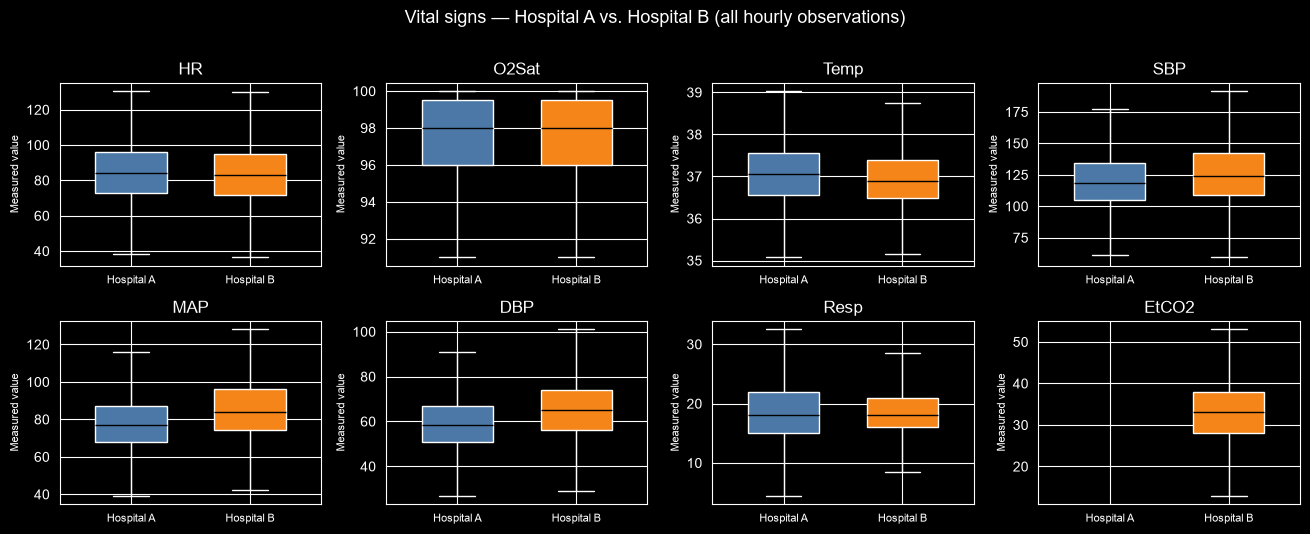

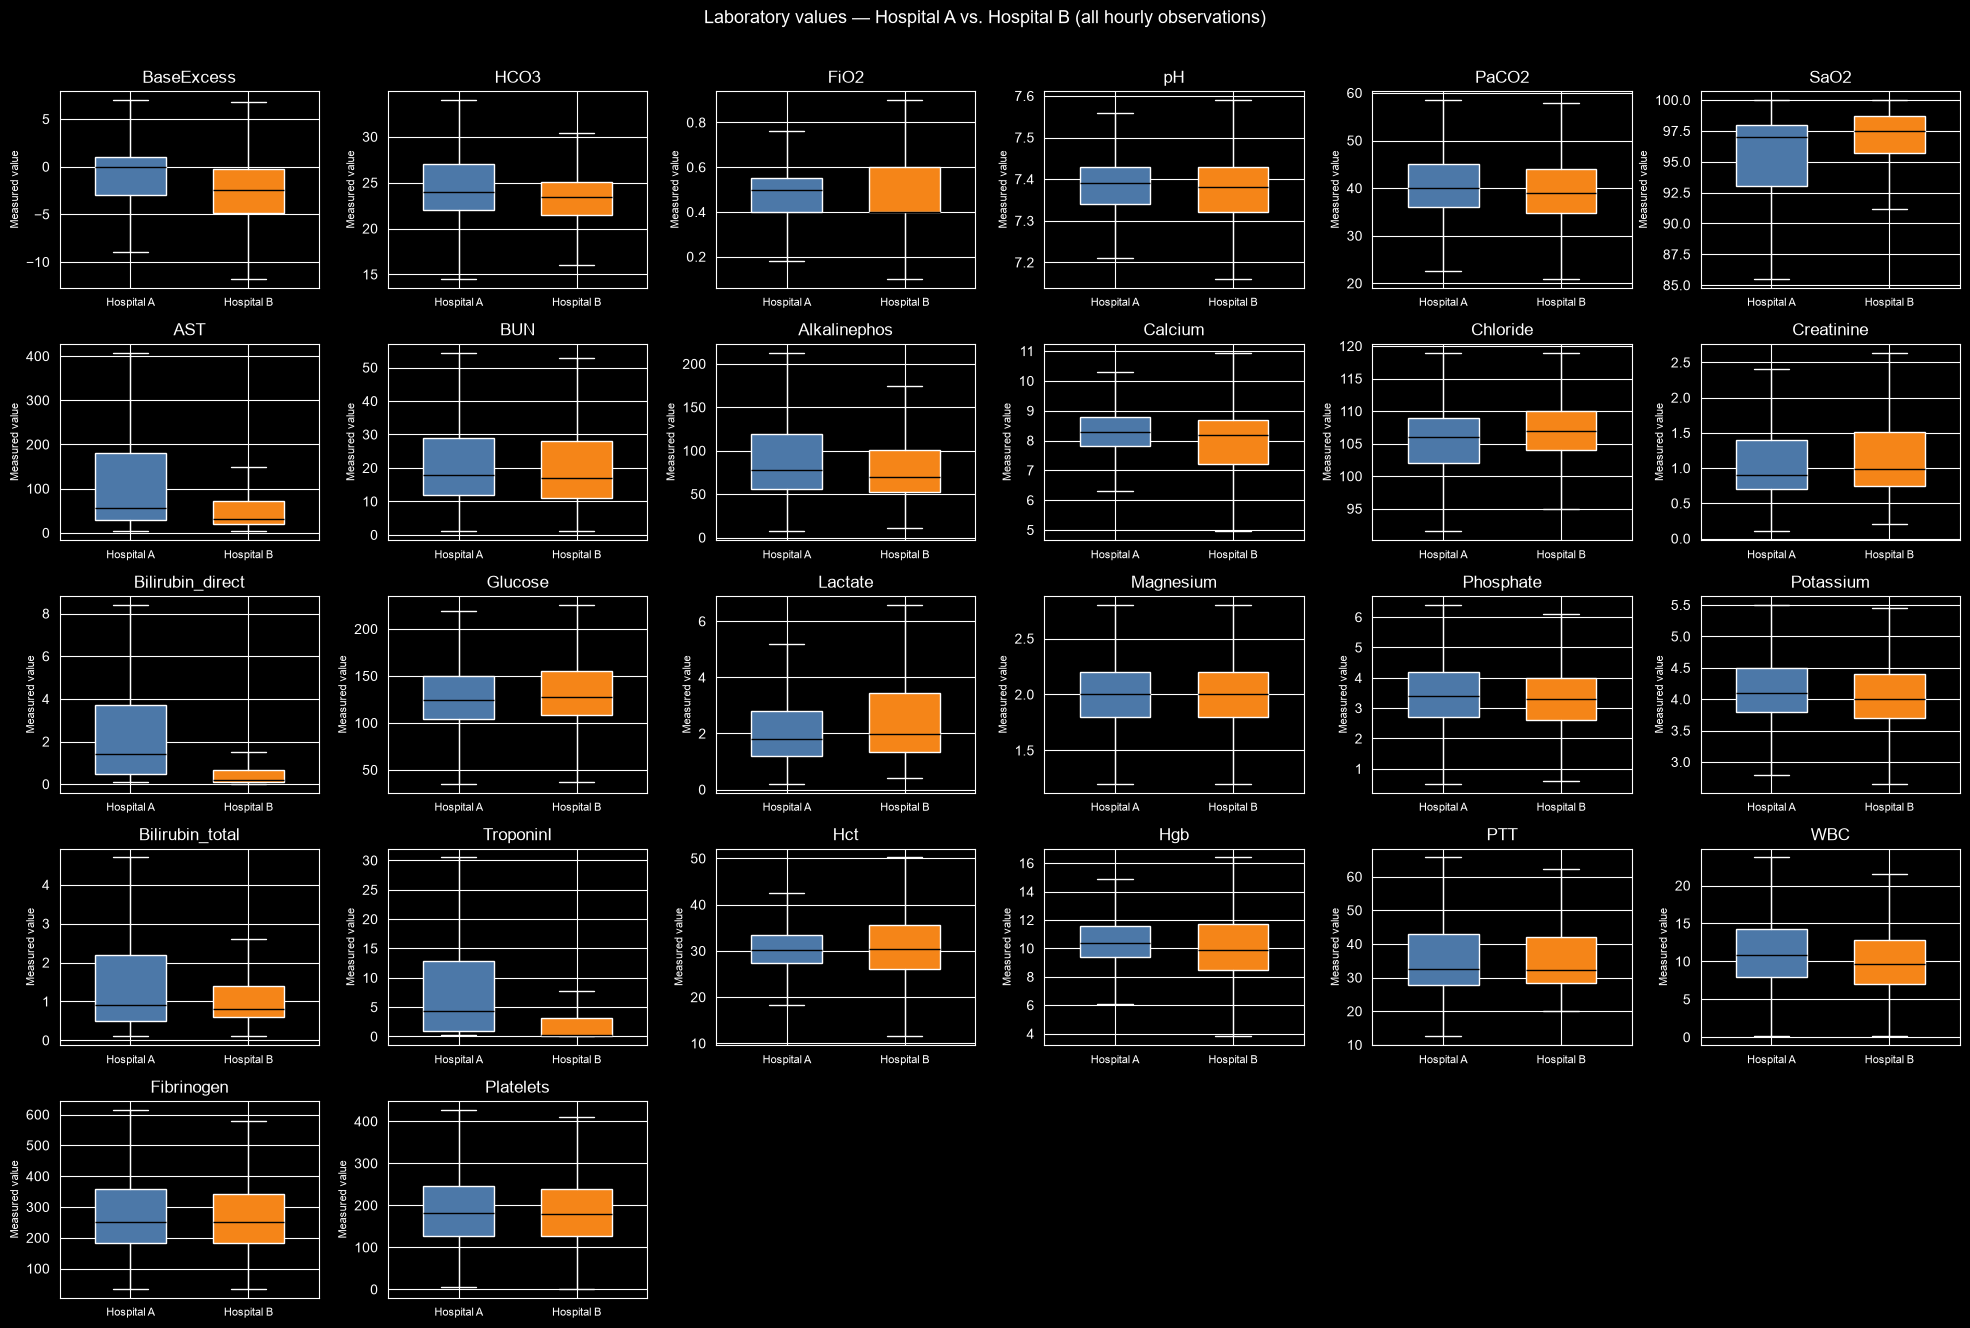

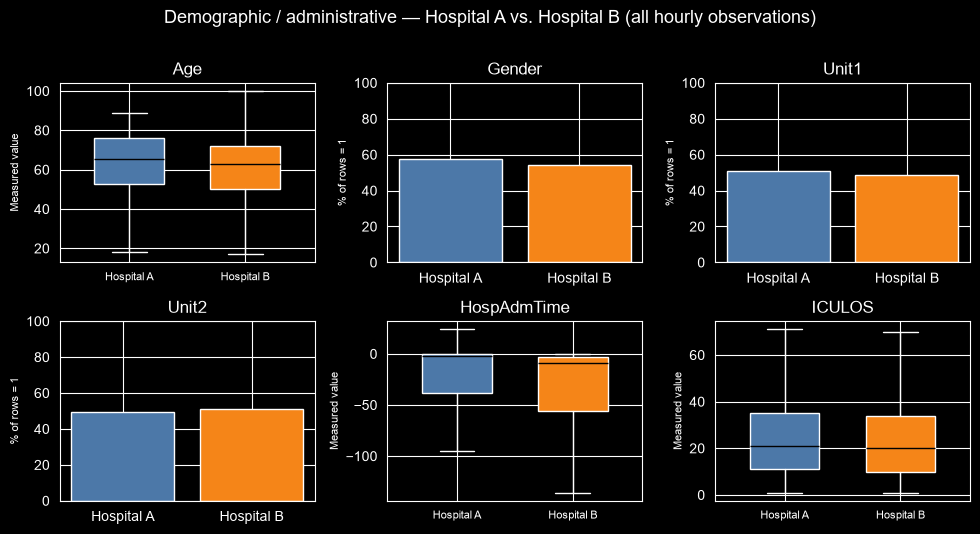

In [16]:
# Comparing feature distributions between hospitals A and B: ALL features
selections = [(hospital, df, None) for hospital, df in HOSPITALS.items()]
compare_all_features(selections, "Hospital A vs. Hospital B (all hourly observations)")

We can see that the mean values are almost similar in both hospitals except for MAP, all these analysis should be done for all features...

In [17]:
# Measurement frequency before sepsis onset: ALL 34 vital/lab features, BOTH hospitals
HOURS = np.arange(-24, 1)     # hours relative to sepsis onset (0 = onset, -6 = first positive label)


def measurement_rate_before_onset(df):
    """% of septic patients that have a measurement of each feature, hour by hour before onset."""
    window = df[df["Septic"] & df["HoursToOnset"].between(-24, 0)]
    measured = window[CLINICAL].notna()
    rate = measured.groupby(window["HoursToOnset"].astype(int).to_numpy()).mean() * 100
    return rate.reindex(HOURS)          # rows = hours, columns = features


measurement_rate = {hospital: measurement_rate_before_onset(df) for hospital, df in HOSPITALS.items()}

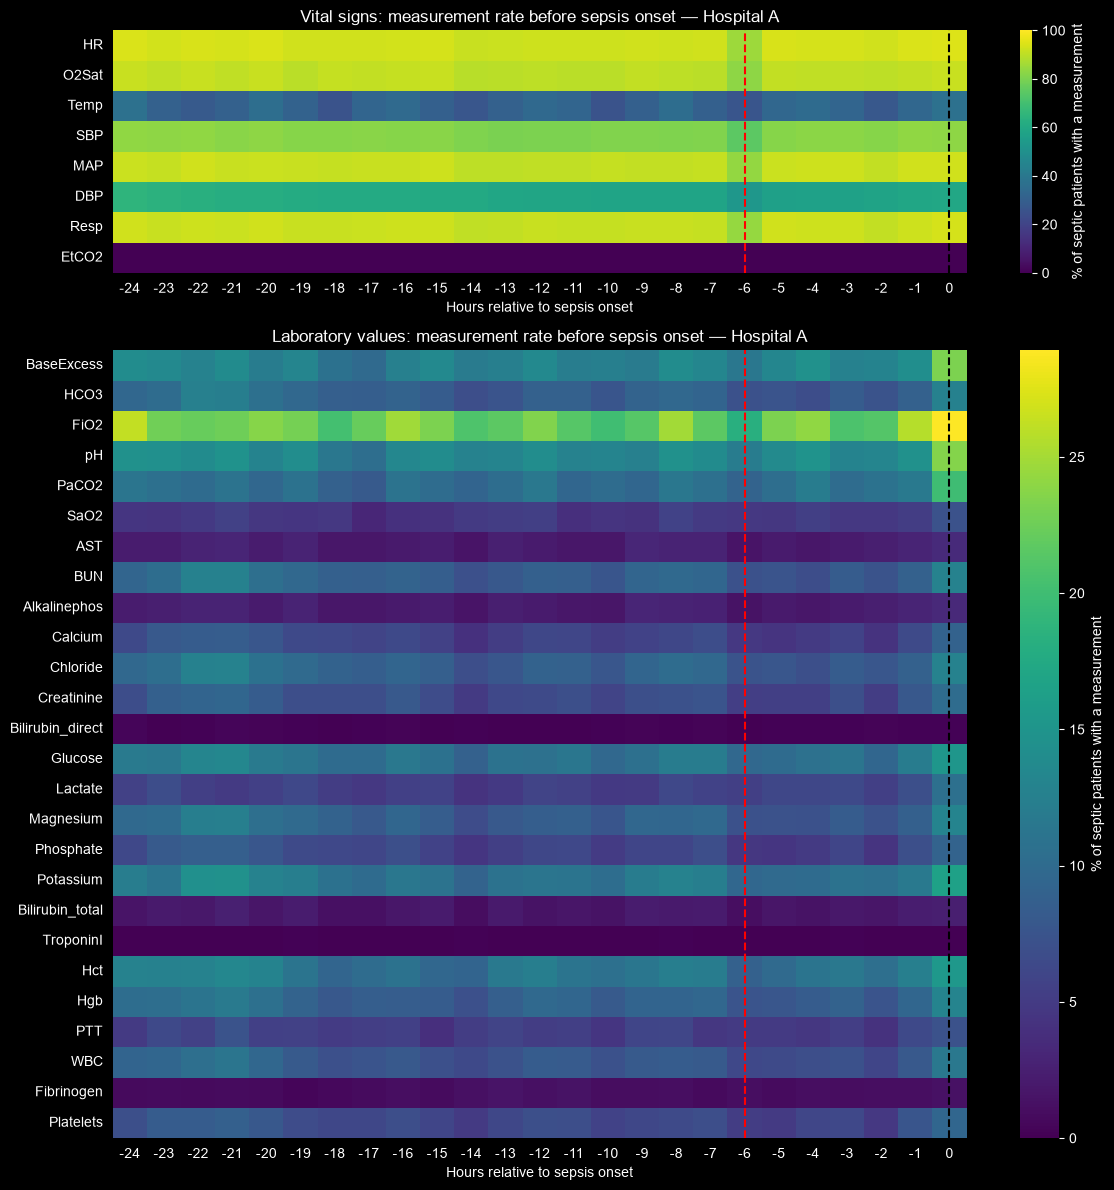

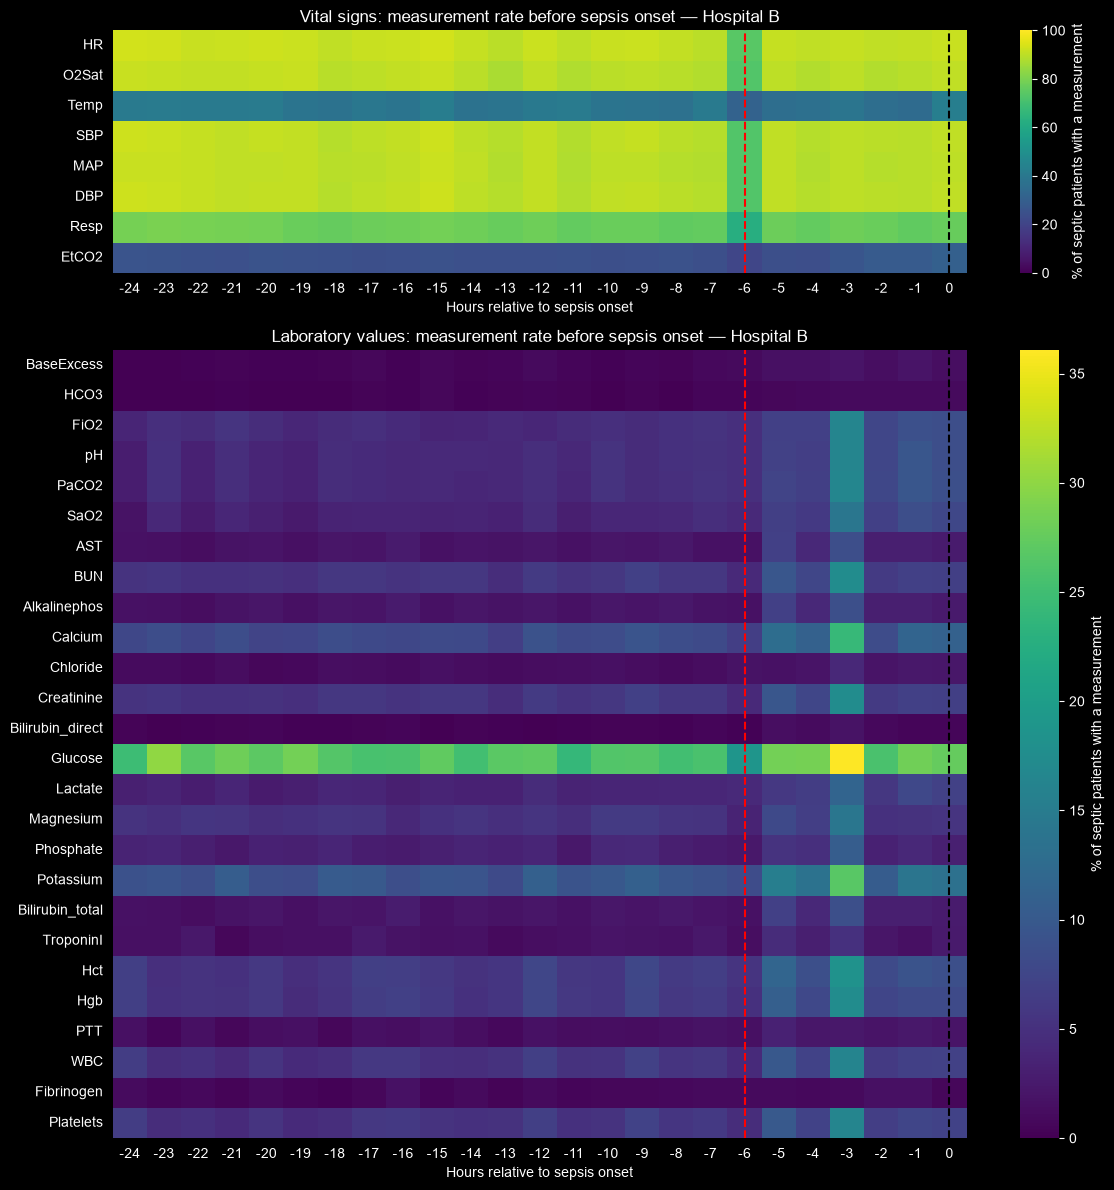

In [18]:
# Heatmaps of the measurement rate (red line: first positive label, black line: onset)
for hospital, rate in measurement_rate.items():
    fig, (ax_vitals, ax_labs) = plt.subplots(2, 1, figsize=(12, 12),
                                             gridspec_kw={"height_ratios": [len(VITALS), len(LABS)]})

    for ax, features in ((ax_vitals, VITALS), (ax_labs, LABS)):
        values = rate[features].T
        top = np.nanmax(values.to_numpy()) if values.notna().any().any() else 1
        sns.heatmap(
            values,
            ax=ax,
            cmap="viridis",
            vmin=0,
            vmax=100 if features is VITALS else max(top, 1),    # labs are measured rarely: own color scale
            cbar_kws={"label": "% of septic patients with a measurement"}
        )
        ax.axvline(list(HOURS).index(-6) + 0.5, color="red", linestyle="--")
        ax.axvline(list(HOURS).index(0) + 0.5, color="black", linestyle="--")
        ax.set_xlabel("Hours relative to sepsis onset")

    ax_vitals.set_title(f"Vital signs: measurement rate before sepsis onset — {hospital}")
    ax_labs.set_title(f"Laboratory values: measurement rate before sepsis onset — {hospital}")
    plt.tight_layout()
    plt.show()

In [19]:
# Feature values before sepsis onset: ALL 34 vital/lab features, BOTH hospitals
MIN_N = 10      # an hour is only drawn if at least this many septic patients have a measurement then


def median_iqr_before_onset(df, features):
    window = df[df["Septic"] & df["HoursToOnset"].between(-24, 0)]
    grouped = window[features].groupby(window["HoursToOnset"].astype(int).to_numpy())

    count = grouped.count().reindex(HOURS)
    stats = {
        "median": grouped.median().reindex(HOURS),
        "q1": grouped.quantile(0.25).reindex(HOURS),
        "q3": grouped.quantile(0.75).reindex(HOURS),
    }
    return {name: table.where(count >= MIN_N) for name, table in stats.items()}


trajectories = {hospital: median_iqr_before_onset(df, CLINICAL) for hospital, df in HOSPITALS.items()}

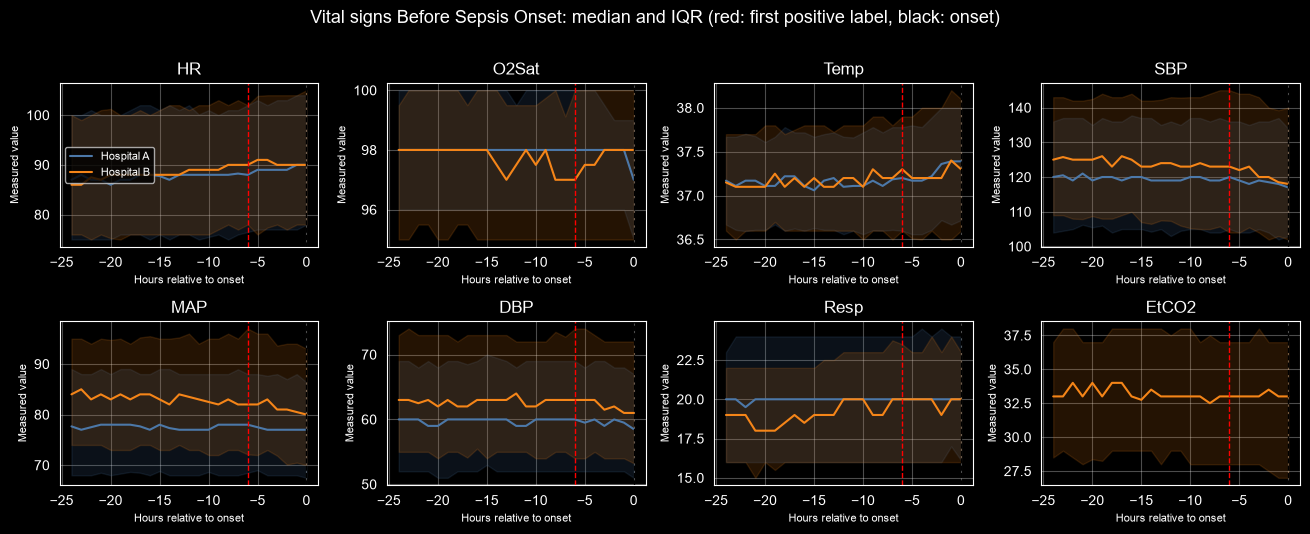

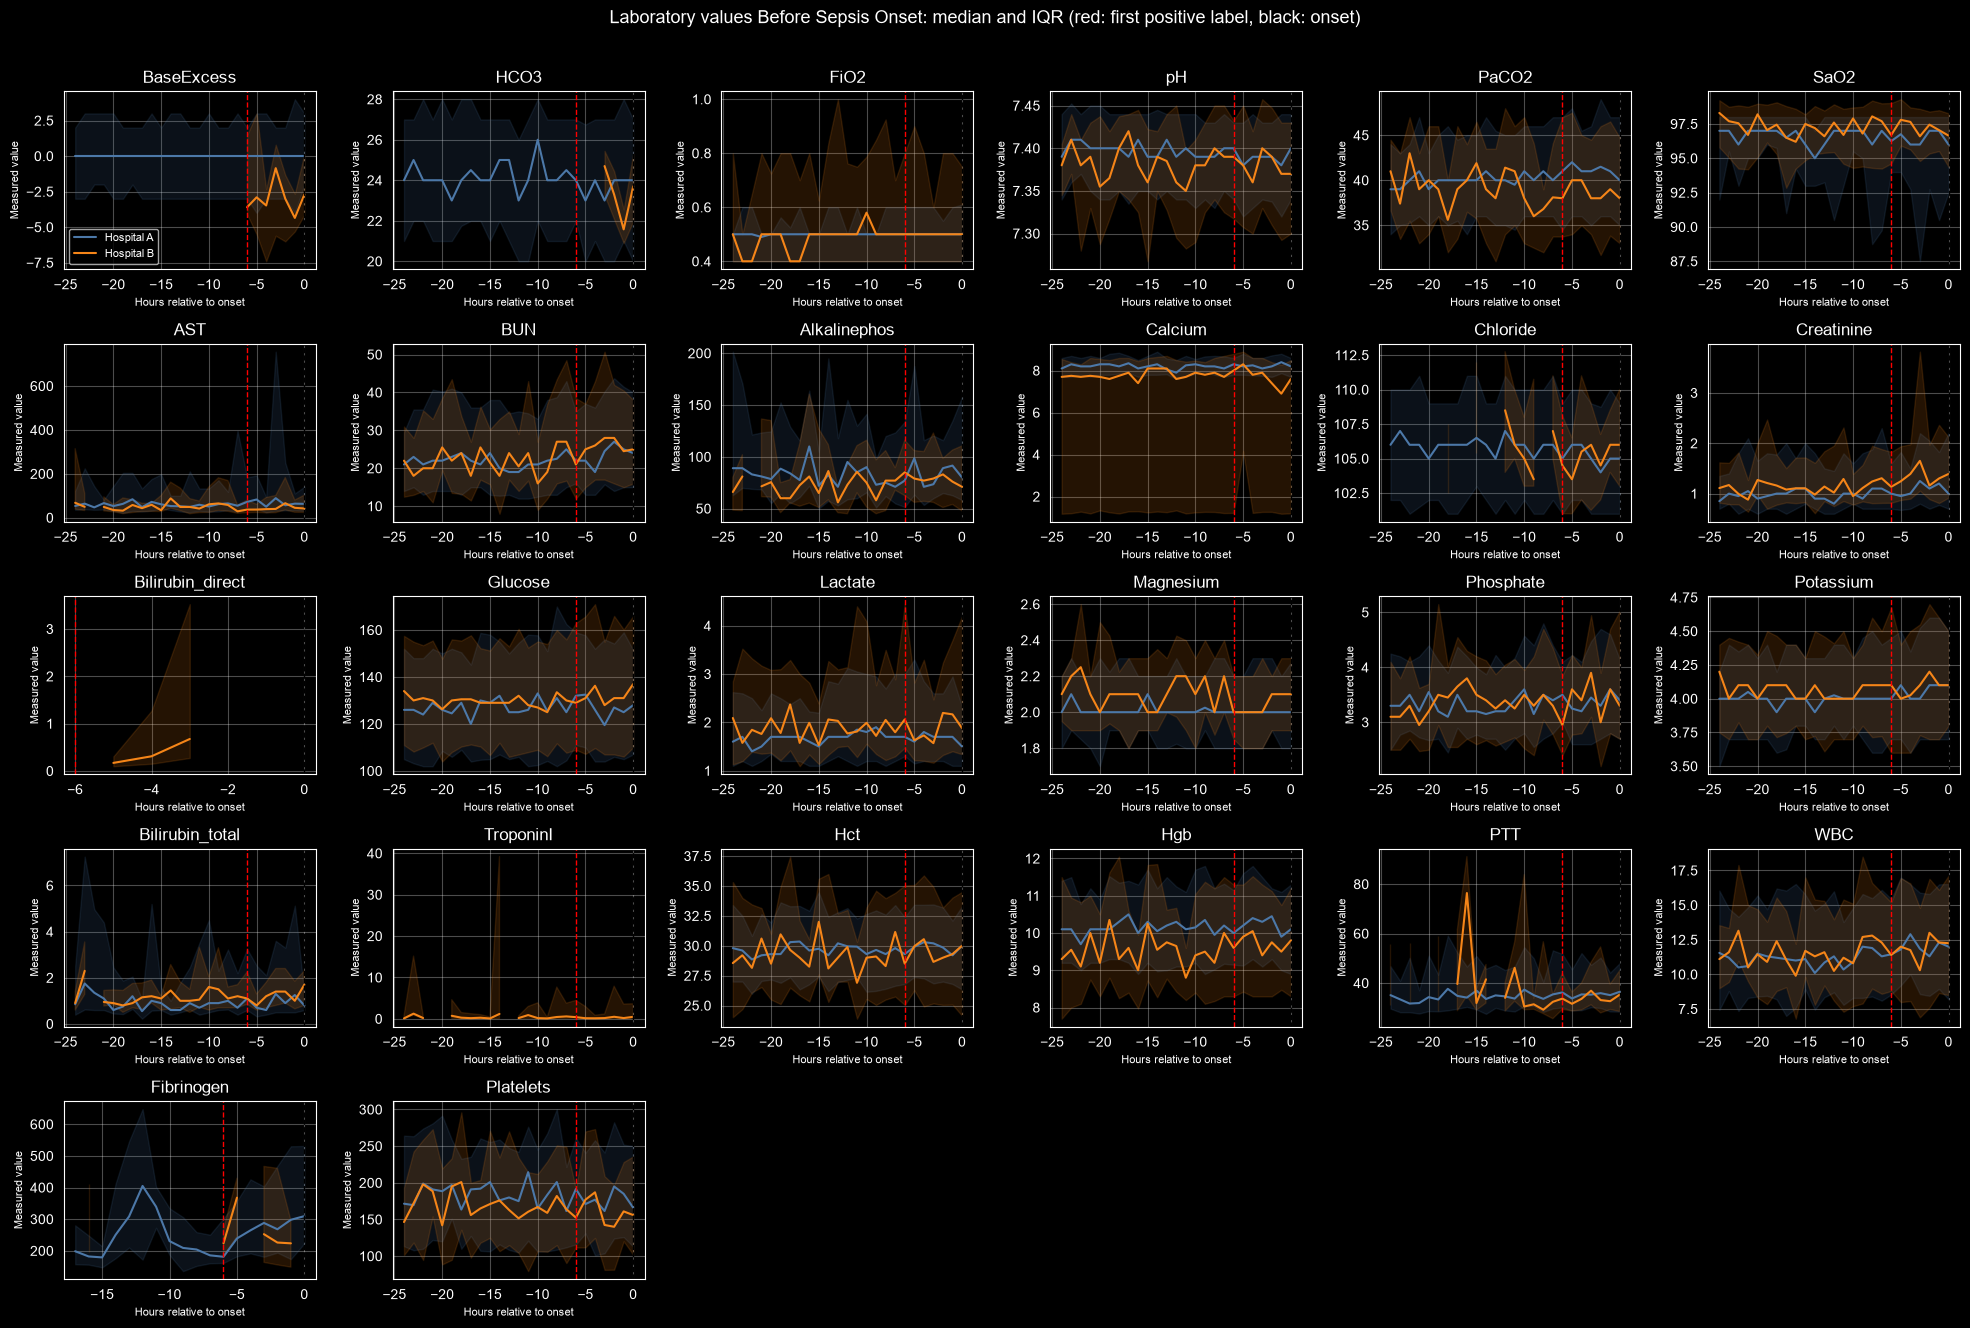

In [20]:
# Median and IQR before sepsis onset, Hospital A vs. Hospital B in the same panel
for group_name in ["Vital signs", "Laboratory values"]:
    features = FEATURE_GROUPS[group_name]
    fig, axes = new_grid(len(features), GROUP_NCOLS[group_name])

    legend_ax = None
    for ax, feature in zip(axes, features):
        ax.set_title(feature)
        if all(stats["median"][feature].isna().all() for stats in trajectories.values()):
            show_no_data(ax, f"not enough data\n(fewer than {MIN_N} values per hour)")
            continue

        for hospital, stats in trajectories.items():
            ax.plot(HOURS, stats["median"][feature], color=COLORS[hospital], label=hospital)
            ax.fill_between(HOURS, stats["q1"][feature], stats["q3"][feature],
                            color=COLORS[hospital], alpha=0.15)

        ax.axvline(-6, color="red", linestyle="--", linewidth=1)
        ax.axvline(0, color="black", linestyle="--", linewidth=1)
        ax.set_xlabel("Hours relative to onset", fontsize=8)
        ax.set_ylabel("Measured value", fontsize=8)
        ax.grid(alpha=0.3)
        legend_ax = legend_ax or ax

    if legend_ax is not None:
        legend_ax.legend(fontsize=8)
    fig.suptitle(f"{group_name} Before Sepsis Onset: median and IQR (red: first positive label, black: onset)",
                 fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    plt.show()

In [21]:
# Sepsis rate by hours in the ICU: BOTH hospitals
def label_rate_by_icu_hour(df):
    hour_group = (df["ICULOS"] // 6) * 6                        # 6-hour intervals
    rate = df.groupby(hour_group)["SepsisLabel"].mean() * 100   # % of positive labels
    observations = df.groupby(hour_group).size()                # hourly observations in each interval
    return rate, observations


icu_rates = {hospital: label_rate_by_icu_hour(df) for hospital, df in HOSPITALS.items()}

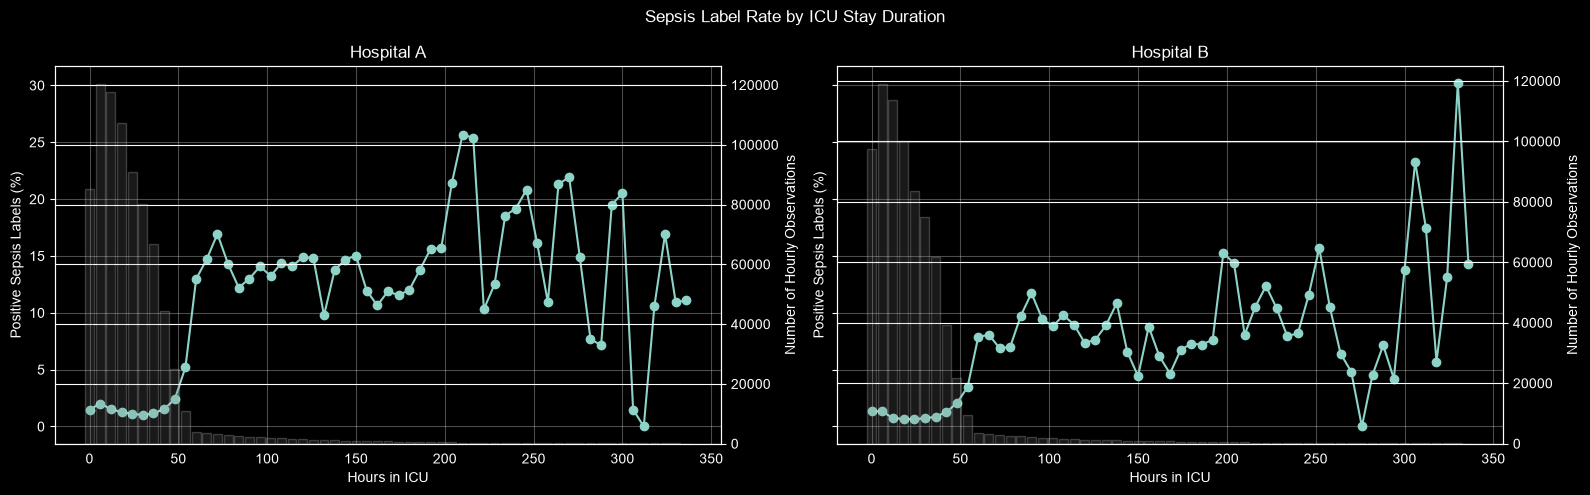

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

for ax1, (hospital, (sepsis_rate, observations)) in zip(axes, icu_rates.items()):
    ax1.plot(sepsis_rate.index, sepsis_rate.values, marker="o")
    ax1.set_xlabel("Hours in ICU")
    ax1.set_ylabel("Positive Sepsis Labels (%)")
    ax1.set_title(hospital)
    ax1.grid(alpha=0.3)

    ax2 = ax1.twinx()
    ax2.bar(observations.index, observations.values, width=5, alpha=0.2, color="gray")
    ax2.set_ylabel("Number of Hourly Observations")

plt.suptitle("Sepsis Label Rate by ICU Stay Duration")
plt.tight_layout()
plt.show()

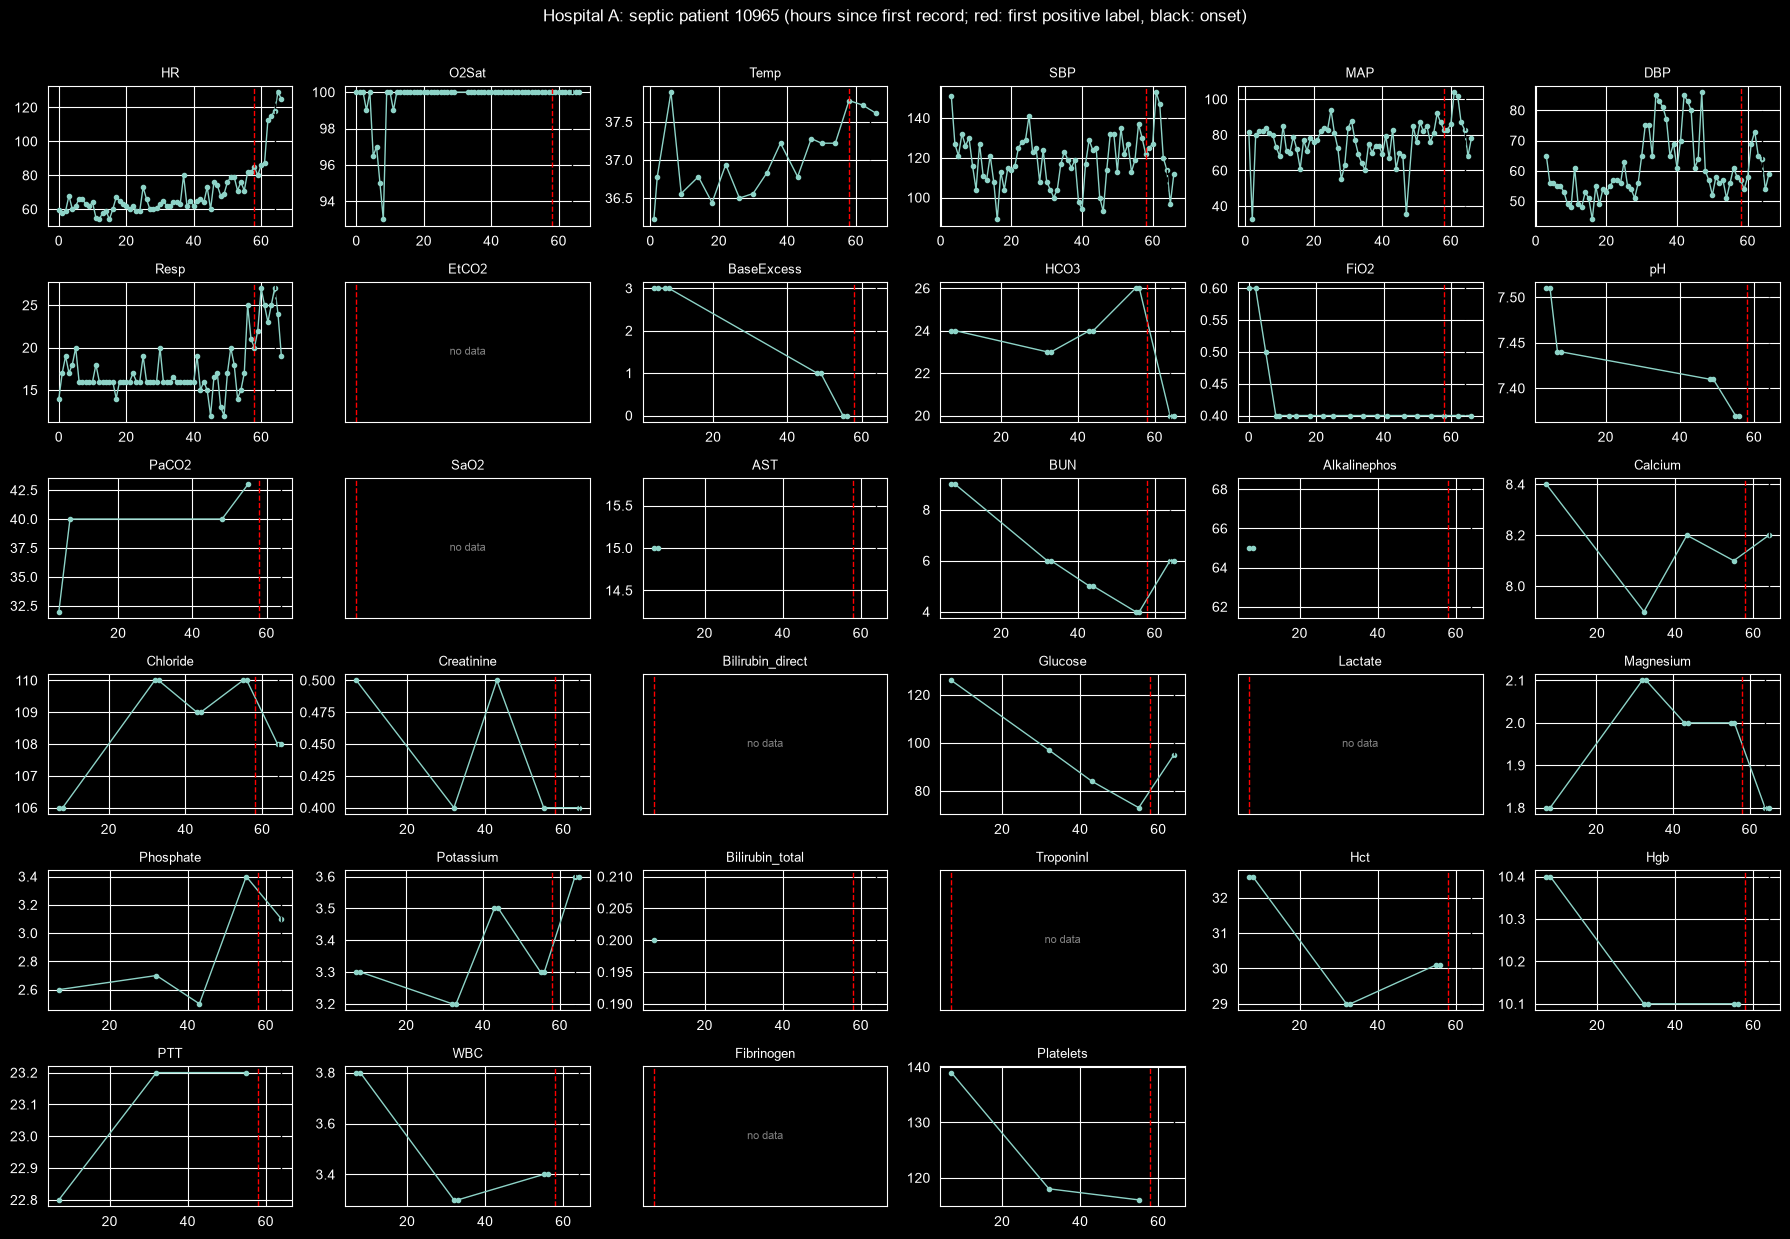

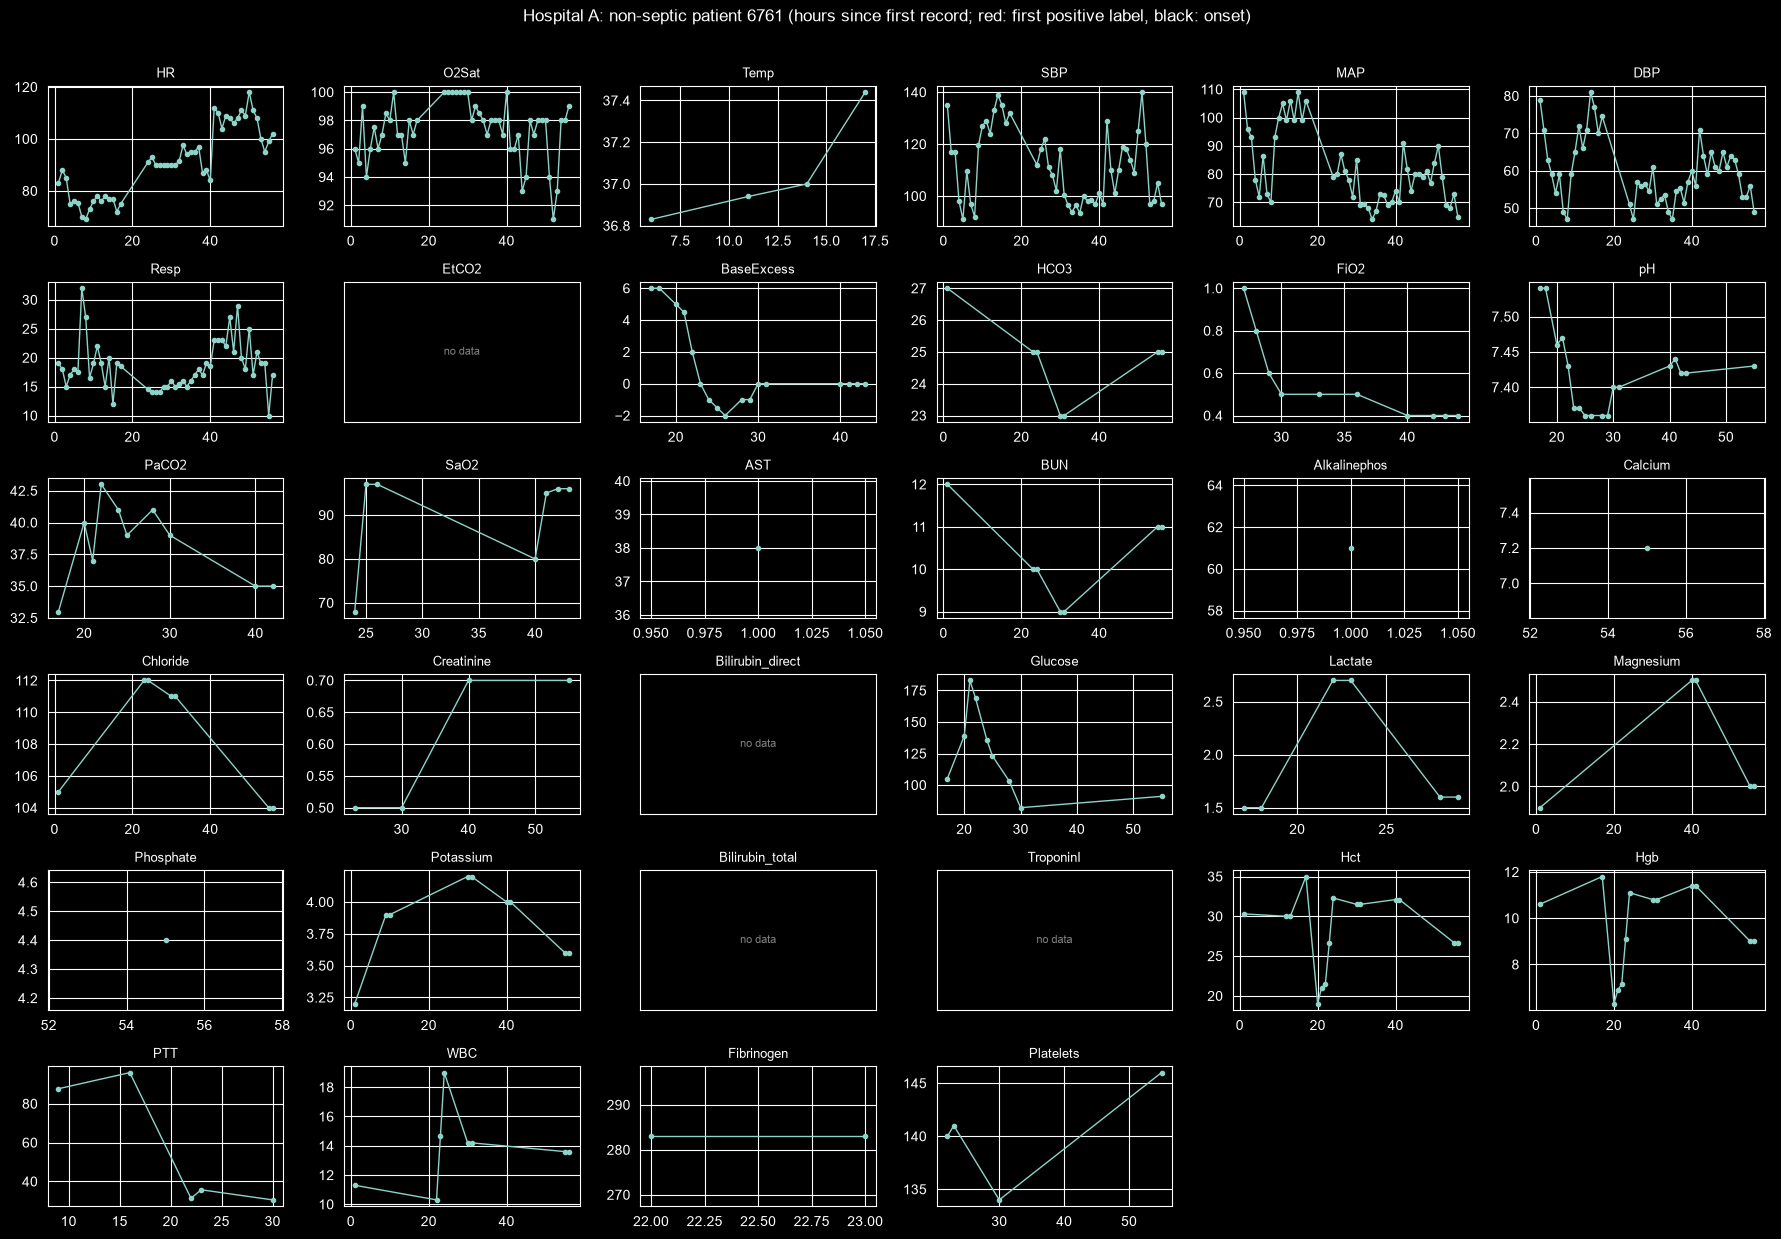

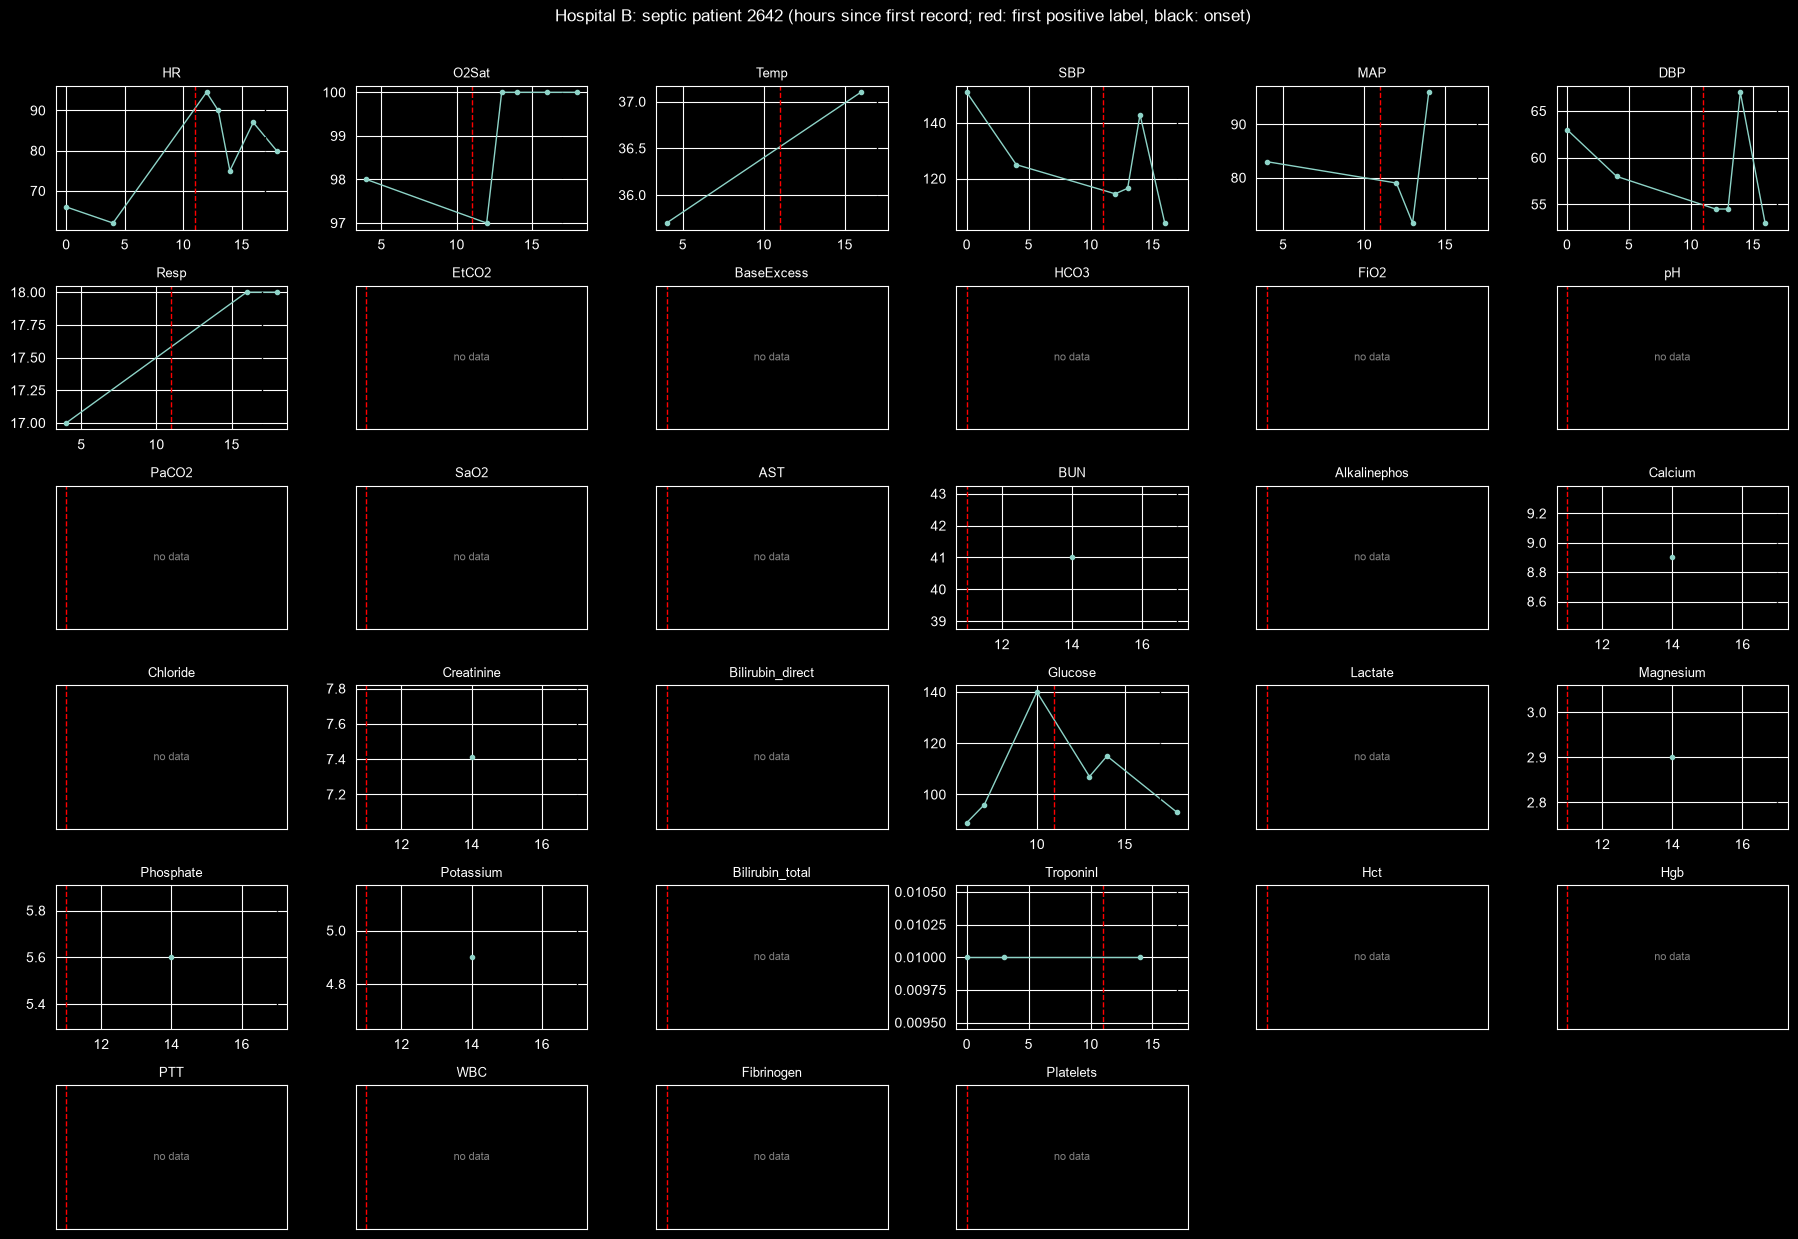

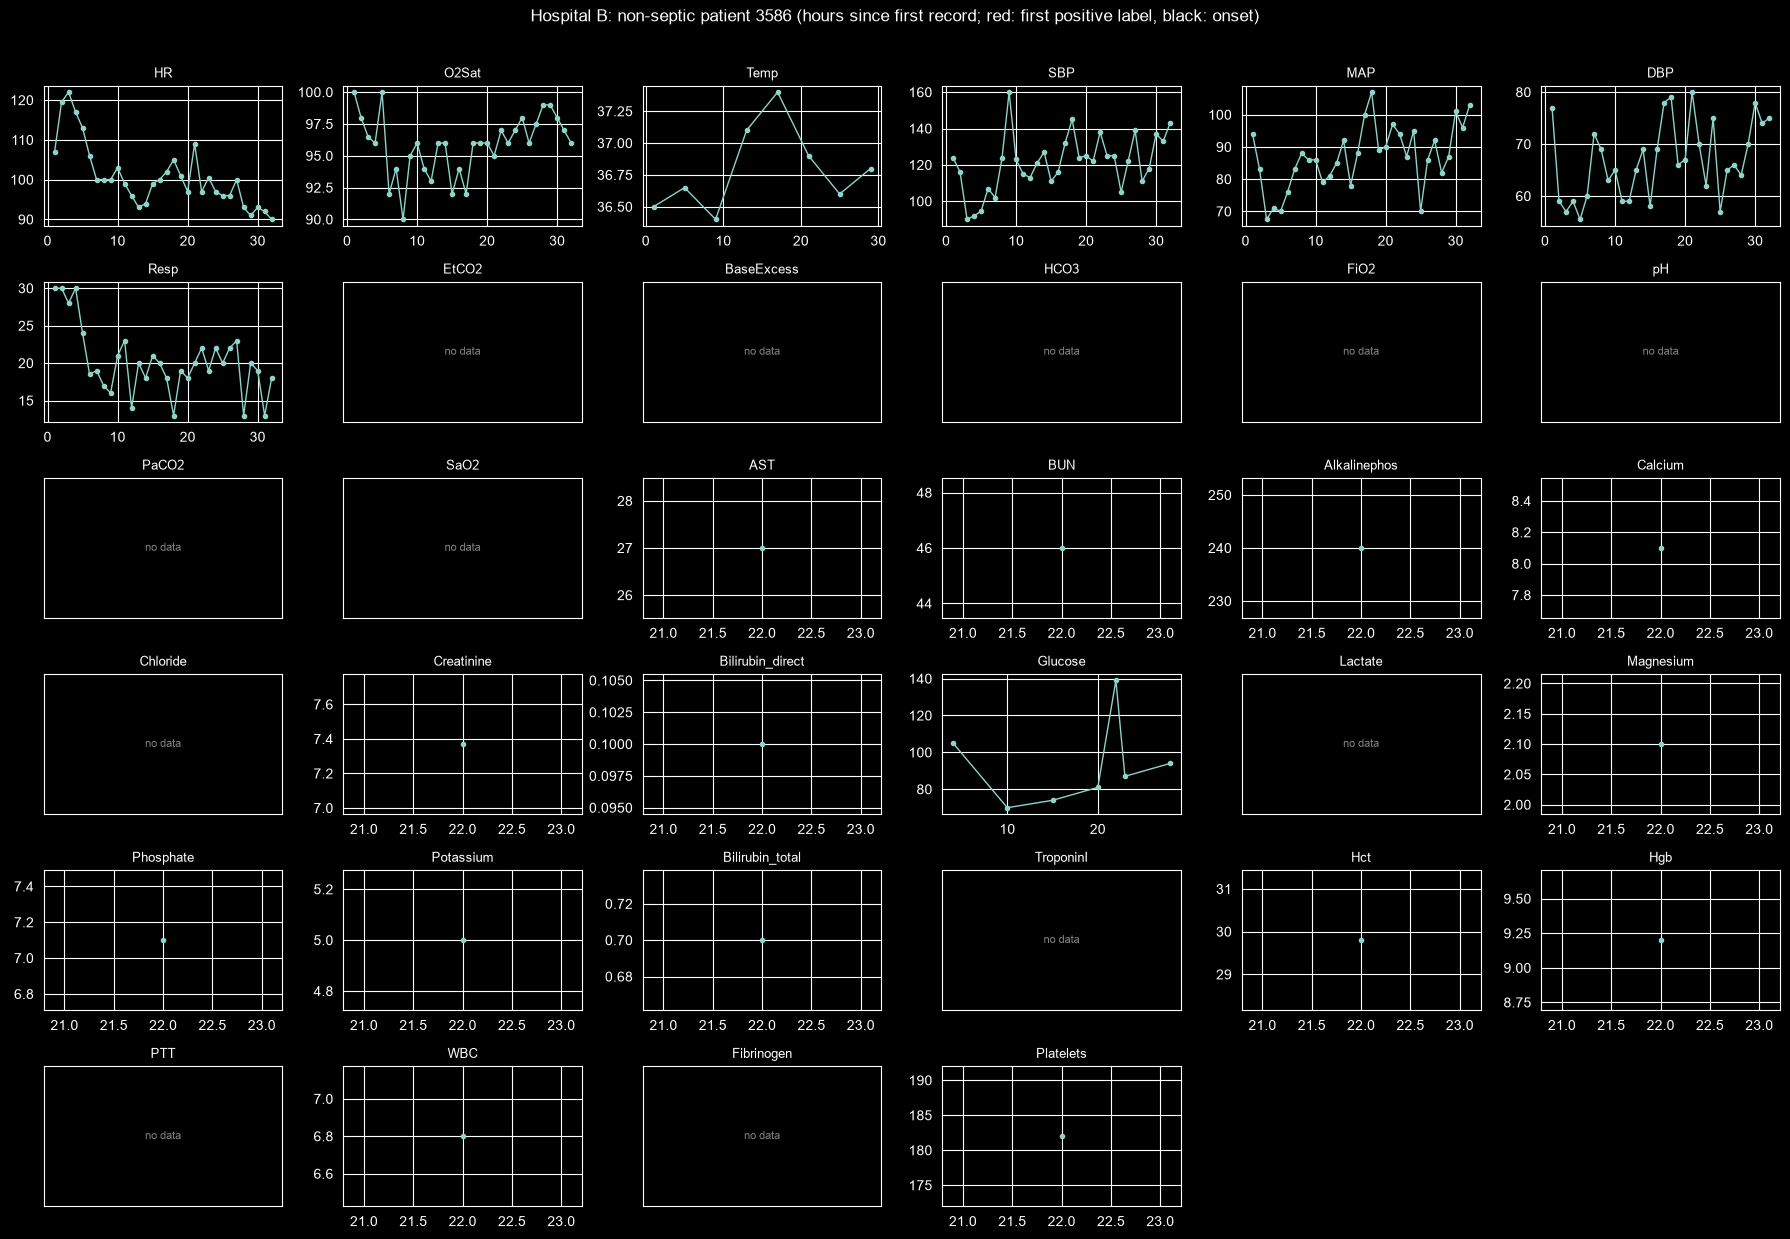

In [23]:
# Individual patient timelines: BOTH hospitals, ALL 34 vital/lab features
selected = {}     # 10 septic + 10 non-septic patients per hospital (same seed as before)

for hospital, df in HOSPITALS.items():
    septic_patient = df.groupby("PatientID")["Septic"].first()
    np.random.seed(42)
    selected[hospital] = {
        "Septic": list(np.random.choice(septic_patient[septic_patient].index.to_numpy(), 10, replace=False)),
        "Non-septic": list(np.random.choice(septic_patient[~septic_patient].index.to_numpy(), 10, replace=False)),
    }


def plot_patient_timeline(df, patient_id, hospital):
    patient = df[df["PatientID"] == patient_id]
    septic = bool(patient["Septic"].iloc[0])

    fig, axes = new_grid(len(CLINICAL), ncols=6, cell=(3.0, 2.1))
    for ax, feature in zip(axes, CLINICAL):
        values = patient[["Hour", feature]].dropna()

        if values.empty:
            show_no_data(ax)
        else:
            ax.plot(values["Hour"], values[feature], marker="o", markersize=3, linewidth=1)

        if septic:
            onset = patient["OnsetHour"].iloc[0]
            ax.axvline(onset - 6, color="red", linestyle="--", linewidth=1)
            ax.axvline(onset, color="black", linestyle="--", linewidth=1)
        ax.set_title(feature, fontsize=9)

    status = "septic" if septic else "non-septic"
    fig.suptitle(f"{hospital}: {status} patient {patient_id} (hours since first record; "
                 f"red: first positive label, black: onset)", fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    plt.show()


# One example patient of each kind per hospital. Use any other ID from selected[hospital][...] to look at more.
for hospital, df in HOSPITALS.items():
    for status in ["Septic", "Non-septic"]:
        plot_patient_timeline(df, selected[hospital][status][0], hospital)

In [24]:
# Temporal variability before sepsis onset: ALL 34 vital/lab features, BOTH hospitals
# = rolling standard deviation over the previous `window` hours, computed only if at least `min_obs`
# measurements fall inside the window.
# Vitals: 6 hours / 3 measurements (as before). Labs are only measured about once a day, so that rule would
# almost never be met; for labs a 24-hour window with at least 2 measurements is used instead.
VARIABILITY_SETTINGS = {
    "Vital signs": dict(features=VITALS, window=6, min_obs=3),
    "Laboratory values": dict(features=LABS, window=24, min_obs=2),
}


def variability_before_onset(df, features, window, min_obs):
    septic = df.loc[df["Septic"], ["PatientID", "Hour", "HoursToOnset"] + features]

    rolling_std = (septic.groupby("PatientID")[features]
                         .rolling(window, min_periods=min_obs).std()
                         .droplevel(0)
                         .reindex(septic.index))

    # hours -24 ... 0 relative to onset, and only windows that lie completely inside the stay
    use = septic["HoursToOnset"].between(-24, 0) & (septic["Hour"] >= window - 1)
    grouped = rolling_std[use].groupby(septic.loc[use, "HoursToOnset"].astype(int).to_numpy())

    count = grouped.count().reindex(HOURS)
    return grouped.median().reindex(HOURS).where(count >= MIN_N)     # hours x features


variability = {
    hospital: {group: variability_before_onset(df, **settings) for group, settings in VARIABILITY_SETTINGS.items()}
    for hospital, df in HOSPITALS.items()
}

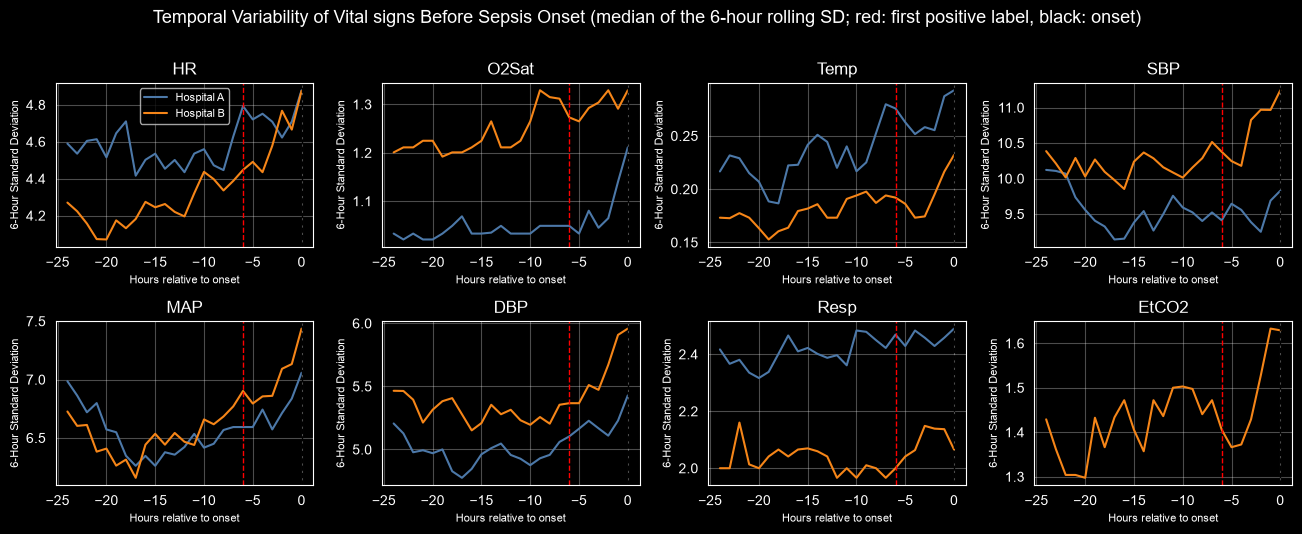

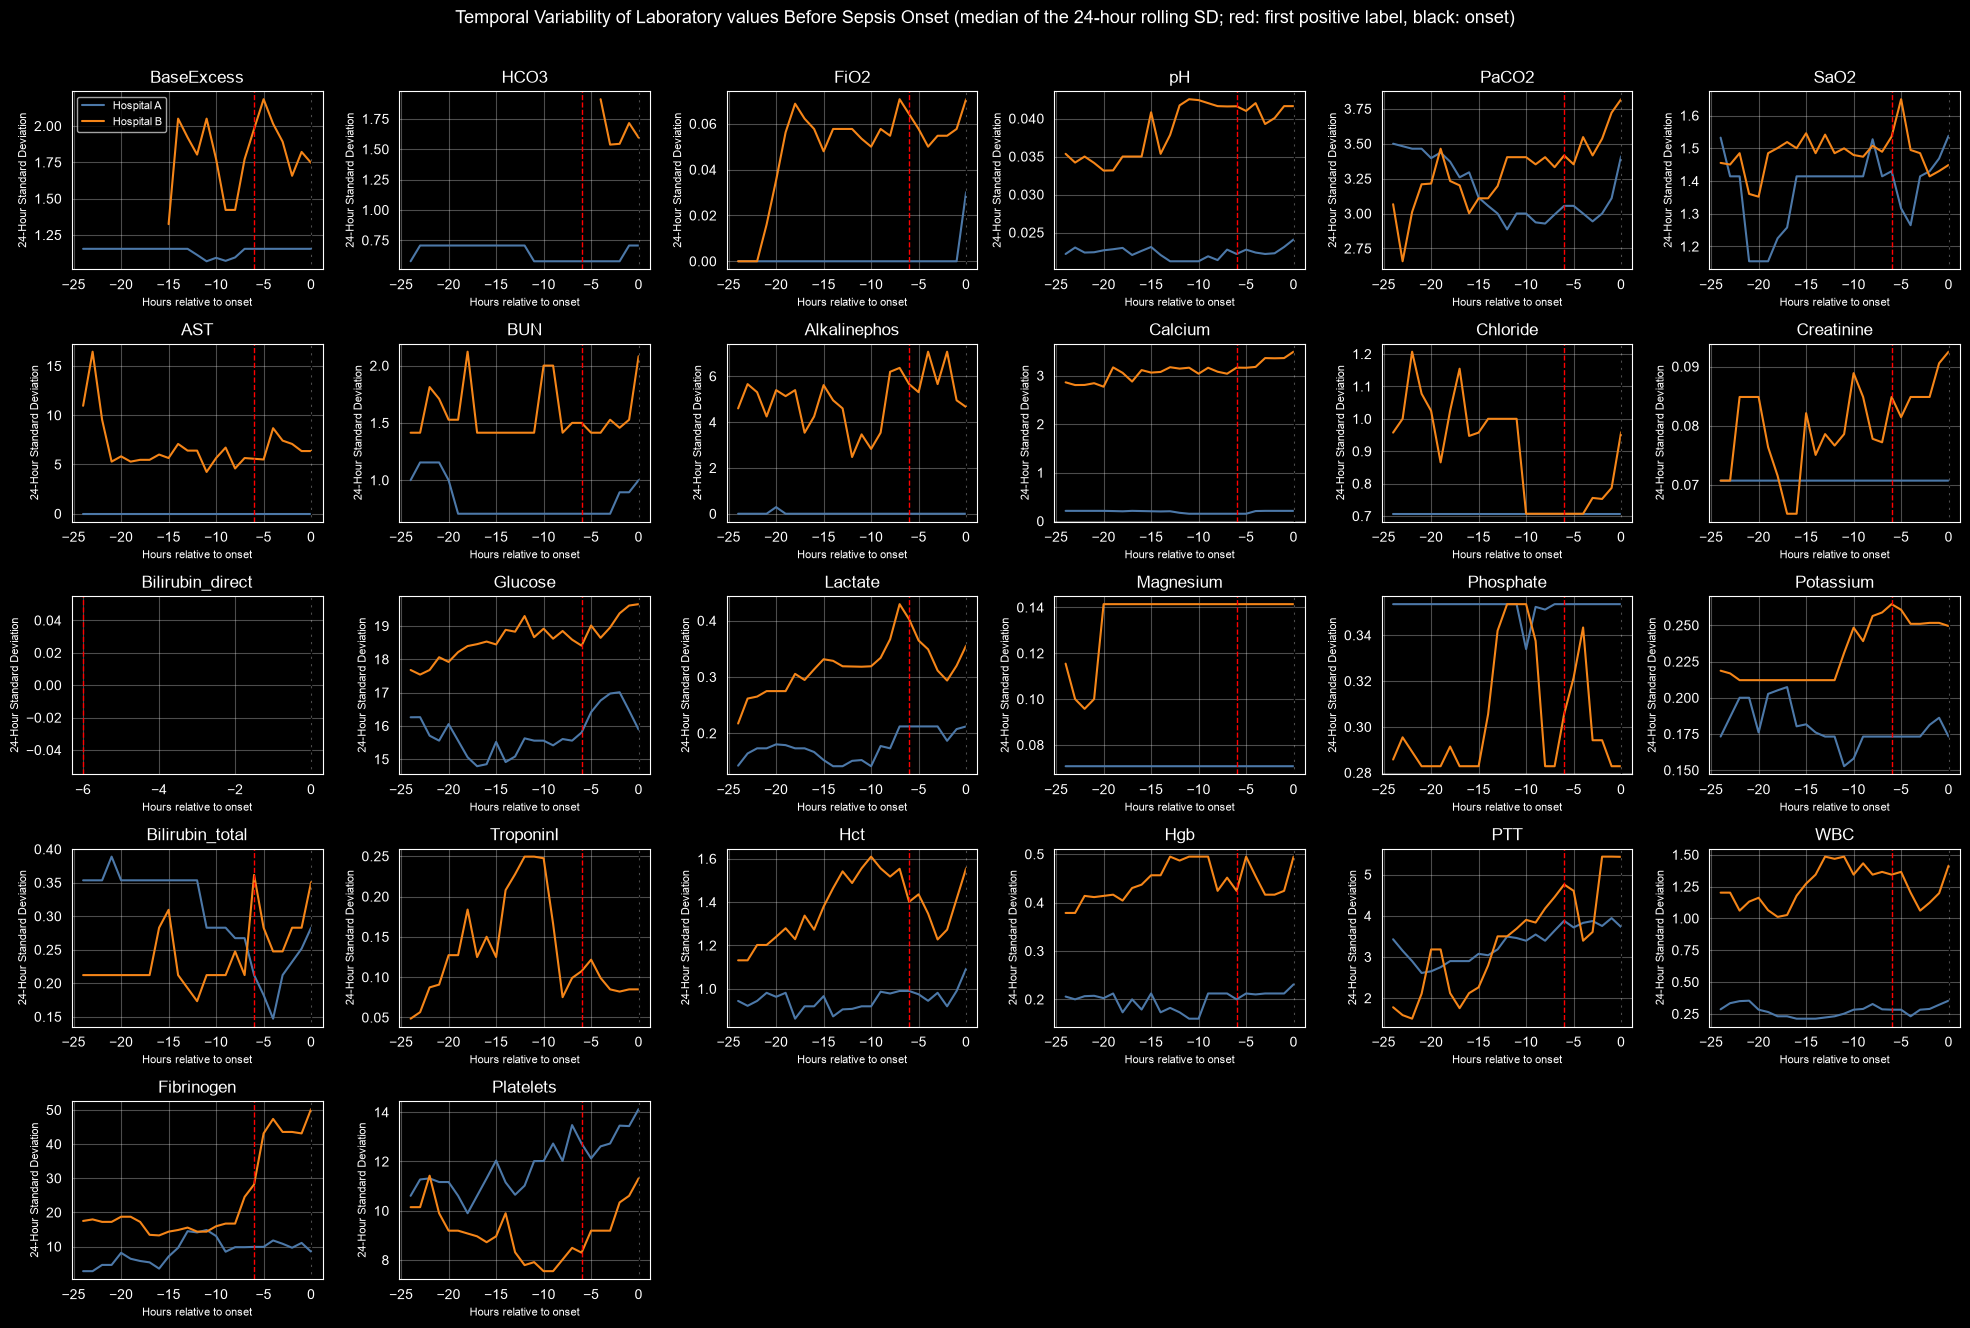

In [25]:
# Median temporal variability before sepsis onset, Hospital A vs. Hospital B in the same panel
for group, settings in VARIABILITY_SETTINGS.items():
    features = settings["features"]
    fig, axes = new_grid(len(features), GROUP_NCOLS[group])

    legend_ax = None
    for ax, feature in zip(axes, features):
        ax.set_title(feature)
        if all(variability[hospital][group][feature].isna().all() for hospital in HOSPITALS):
            show_no_data(ax, f"not enough data\n(fewer than {MIN_N} values per hour)")
            continue

        for hospital in HOSPITALS:
            ax.plot(HOURS, variability[hospital][group][feature], color=COLORS[hospital], label=hospital)

        ax.axvline(-6, color="red", linestyle="--", linewidth=1)
        ax.axvline(0, color="black", linestyle="--", linewidth=1)
        ax.set_xlabel("Hours relative to onset", fontsize=8)
        ax.set_ylabel(f"{settings['window']}-Hour Standard Deviation", fontsize=8)
        ax.grid(alpha=0.3)
        legend_ax = legend_ax or ax

    if legend_ax is not None:
        legend_ax.legend(fontsize=8)
    fig.suptitle(f"Temporal Variability of {group} Before Sepsis Onset "
                 f"(median of the {settings['window']}-hour rolling SD; red: first positive label, black: onset)",
                 fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    plt.show()

These graphs show how the variability of clinical measurements changes during the 24 hours before sepsis onset in both hospitals. We can see that for most vital signs the standard deviation does not change that much, however some features start showing an increase as sepsis onset approaches. For example HR variability increases slightly in both hospitals while MAP and DBP increase more in Hospital B. One thing that is interesting is that some features have different variability between hospitals, like O2Sat which is more variable in Hospital B while respiratory rate is more variable in Hospital A.

For laboratory measurements the differences between hospitals are much larger. We can see that features like glucose, WBC, Hct and Hgb have much higher variability in Hospital B. Also some features like glucose, creatinine and fibrinogen seem to become more variable as sepsis onset approaches. Could this mean that the changes in these features could help us predict sepsis earlier?

However we need to remember that most laboratory measurements have very high missingness percentages, which means that these standard deviations might be calculated using only a few patients. This could explain why some graphs are almost flat while others have sudden changes. So we cannot really know if these differences are related to the patients themselves or simply because of how often the measurements are taken.

Overall we can see that looking at how the features change over time might be useful instead of only looking at their values at a certain hour. However we are only looking at patients who develop sepsis here, so we still need to compare these changes with patients who do not develop sepsis to see if these patterns are actually related to sepsis.


In [26]:
# Feature availability by clinical group and ICU hour: BOTH hospitals
groups = {
    "Vital Signs": VITALS,
    "Laboratory Measurements": LABS,
    "Demographics": DEMOGRAPHICS
}

availability = {}

for hospital, df in HOSPITALS.items():
    hour_group = (df["ICULOS"] // 6) * 6

    # share of the features of each group that are available in each row, averaged per 6-hour interval
    per_row = pd.DataFrame({name: df[columns].notna().mean(axis=1) * 100
                            for name, columns in groups.items()})
    availability[hospital] = per_row.groupby(hour_group).mean()

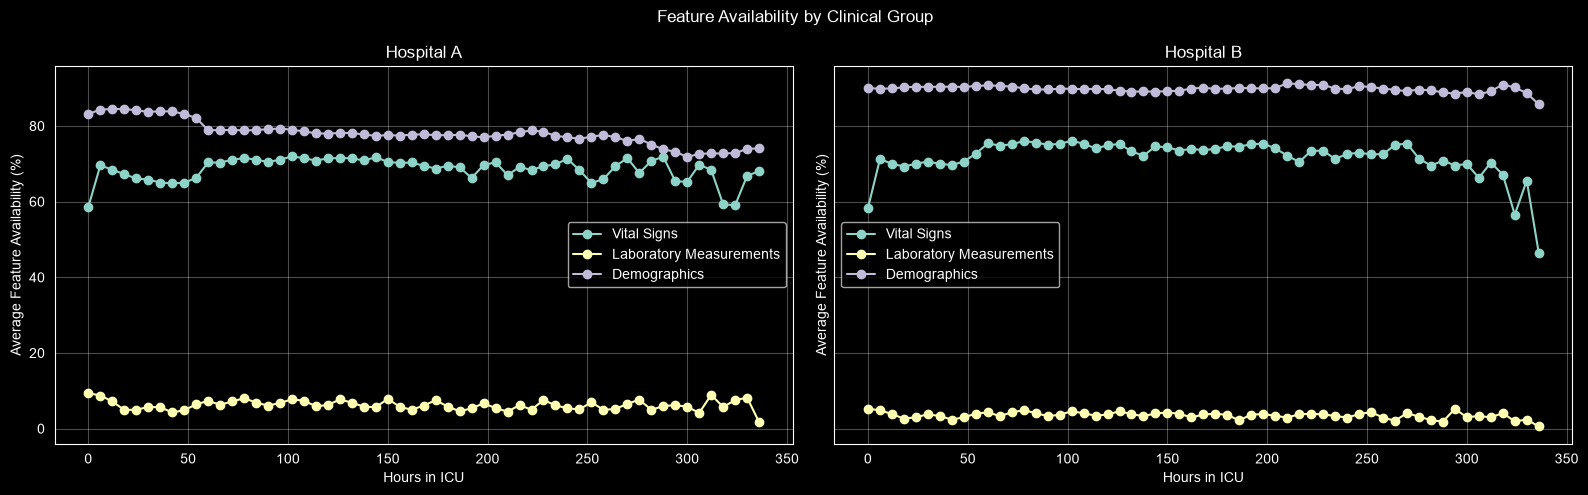

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

for ax, (hospital, table) in zip(axes, availability.items()):
    for group in table.columns:
        ax.plot(table.index, table[group], marker="o", label=group)

    ax.set_xlabel("Hours in ICU")
    ax.set_ylabel("Average Feature Availability (%)")
    ax.set_title(hospital)
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("Feature Availability by Clinical Group")
plt.tight_layout()
plt.show()

From these graphs we can see that vital signs are much more available than laboratory measurements in both hospitals, which is something we already noticed from the missingness heatmap. Laboratory measurements have a very low availability, around 5% in Hospital A and even less in Hospital B. One thing that is interesting is that their availability does not really increase as the patient spends more time in the ICU, it stays almost the same throughout the stay. This could mean that laboratory tests are not necessarily taken more frequently just because a patient has been in the ICU for longer.

For vital signs, we can see that their availability is around 65-75% in both hospitals, with Hospital B having slightly higher availability for most of the ICU stay. We also notice that there are some fluctuations but no major changes over time. However towards the end, especially in Hospital B, the availability starts decreasing. This could be because fewer patients remain in the dataset at these later hours, so the results might be less reliable.

Another thing we can notice is that demographic features are more available in Hospital B than in Hospital A, around 90% compared to around 80%. This is probably related to the differences in missingness of Unit1 and Unit2 that we noticed earlier, since the other demographic features are almost always present.

Overall, we can see that the availability of features does not change much with ICU duration, and that the main difference is between the feature groups themselves rather than how long the patient stays in the ICU. This makes us wonder whether laboratory measurements, despite being so rarely available, could still improve sepsis prediction compared to using vital signs alone. It also shows why comparing different feature groups is important for our project.
